# Downstream analysis

Paper-facing downstream classification tables and figures. HEST excludes TENX143. Hibou-L is excluded entirely, and LEMON refers only to the ViT-S/8 checkpoint. The paper-facing CellBridge all/adapted representation is labeled simply as CellBridge.

## Imports

In [1]:
import os
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 100)

WORKSPACE = Path(os.environ.get(
    "CELLBRIDGE_WORKSPACE",
    "/lustre/scratch126/cellgen/lotfollahi/so25",
))
RESULTS_ROOT = Path(os.environ.get(
    "CELLBRIDGE_INFERENCE_RESULTS",
    WORKSPACE / "outputs/reproducibility/inference",
))
FIGURE_DIR = Path(os.environ.get(
    "CELLBRIDGE_DOWNSTREAM_FIGURES",
    WORKSPACE / "outputs/reproducibility/figures/downstream",
))

ID_DATASETS = ["hest"]
OOD_DATASETS = ["lizard", "nucls", "pannuke", "phenocell"]
DATASET_LABELS = {
    "hest": "HEST",
    "lizard": "Lizard",
    "nucls": "NuCLS",
    "pannuke": "PanNuke",
    "phenocell": "PhenoCell",
}

BASELINE_LABELS = {
    "uni": "UNI2-h",
    "virchow2": "Virchow2",
    "lemon": "LEMON",
    "past": "PAST",
    "volta": "VOLTA",
    "spatialwhisperer": "SpatialWhisperer",
}
LEMON_VERSION = "vits8"
BASELINE_VERSIONS = {method: "all" for method in BASELINE_LABELS}
BASELINE_VERSIONS["lemon"] = LEMON_VERSION
CELLBRIDGE_METHODS = [
    "CellBridge" if size == "all" and arm == "adapted"
    else f"CellBridge {size} ({arm})"
    for size in ("5K", "10K", "50K", "all")
    for arm in ("adapted", "projected")
]
EXPECTED_METHODS = list(BASELINE_LABELS.values()) + CELLBRIDGE_METHODS

EXCLUDED_METHODS = {"hibou_l"}
EXCLUDED_HEST_SAMPLES = {"TENX143"}

METHOD_GROUPS = [
    ("Patch-level FMs", ["UNI2-h", "Virchow2"]),
    ("Cell-level FMs", ["VOLTA", "LEMON"]),
    ("Multimodal FMs", ["PAST", "SpatialWhisperer"]),
    ("Ours", CELLBRIDGE_METHODS),
]
# The combined table carries one representative per family.
FINAL_METHOD_GROUPS = [
    ("Patch-level FMs", ["UNI2-h", "Virchow2"]),
    ("Cell-level FMs", ["VOLTA", "LEMON"]),
    ("Multimodal FMs", ["PAST", "SpatialWhisperer"]),
    ("Ours", ["CellBridge"]),
]
SHADED_GROUP = "Ours"
ROW_COLOUR = "gray!15"  # \rowcolor needs \usepackage[table]{xcolor}

# (dataset, task, column label) for the combined table.
FINAL_COLUMNS = [
    ("hest", "all", "HEST"),
    ("lizard", "all", "Lizard"),
    ("nucls", "all", "NuCLS"),
    ("pannuke", "all", "PanNuke"),
    ("phenocell", "all", "PhenoCell\\textsubscript{all}"),
    ("phenocell", "immune", "PhenoCell\\textsubscript{imm}"),
]

CLASSIFICATION_METRICS = ["macro_f1", "balanced_accuracy", "macro_auroc"]
METRIC_LABELS = {
    "macro_f1": "Macro F1",
    "balanced_accuracy": "Balanced accuracy",
    "macro_auroc": "Macro AUROC",
}
PROBES = ["linear", "knn"]
TASK = "all"  # Change to "immune" for the PhenoCell immune-only task.
HEST_COMMON_SAMPLES = True  # Compare methods on their shared retained HEST sections.
SAVE_FIGURES = True

missing_tex = [name for name in ("latex", "dvipng") if shutil.which(name) is None]
if missing_tex:
    raise RuntimeError(
        "Full LaTeX rendering requires: module load texlive-20220321 "
        f"(missing {', '.join(missing_tex)})"
    )
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT

PosixPath('/lustre/scratch126/cellgen/lotfollahi/so25/outputs/reproducibility/inference')

## Load results

A run is expected at `<method>/<version>/<dataset>` for OOD and `<method>/<version>/hest/<sample>` for separately submitted HEST jobs. Baseline versions are normally `all`; LEMON ViT-B/8 uses `vitb8`; CellBridge versions are `cells_5k`, `cells_10k`, `cells_50k`, and `cells_all`.

In [2]:
def _require_columns(table, columns, path):
    missing = set(columns) - set(table.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")


def _normalise_id(value):
    return str(value).strip().lower().replace("-", "_")


def paper_method(method, version, arm):
    method_id = _normalise_id(method)
    arm_id = _normalise_id(arm)
    version_id = _normalise_id(version)
    if method_id == "cellbridge" or arm_id.startswith("lora_"):
        size = version_id.removeprefix("cells_")
        size = size.upper() if size != "all" else "all"
        representation = arm_id.removeprefix("lora_")
        if size == "all" and representation == "adapted":
            return "CellBridge"
        return f"CellBridge {size} ({representation})"

    label = BASELINE_LABELS.get(method_id, str(method))
    if version_id != BASELINE_VERSIONS.get(method_id, "all"):
        label = f"{label} [{version}]"
    if arm_id not in {method_id, "default"}:
        label = f"{label} ({arm})"
    return label


def iter_runs(root):
    if not root.exists():
        raise FileNotFoundError(f"Results root does not exist: {root}")
    for method_dir in sorted(path for path in root.iterdir() if path.is_dir()):
        for version_dir in sorted(path for path in method_dir.iterdir() if path.is_dir()):
            for dataset_dir in sorted(path for path in version_dir.iterdir() if path.is_dir()):
                dataset = dataset_dir.name
                if (dataset_dir / "evaluation").is_dir():
                    yield method_dir.name, version_dir.name, dataset, None, dataset_dir
                elif dataset == "hest":
                    for sample_dir in sorted(path for path in dataset_dir.iterdir() if path.is_dir()):
                        if (sample_dir / "evaluation").is_dir():
                            yield (
                                method_dir.name, version_dir.name, dataset,
                                sample_dir.name, sample_dir,
                            )


def _contextualise(table, path, method, version, dataset, sample_id, arm, task, probe):
    table = table.copy()
    context = {
        "method": method, "version": version, "dataset": dataset,
        "arm": arm, "task": task, "probe": probe,
    }
    for column, expected in context.items():
        if column in table and not (table[column].astype(str) == str(expected)).all():
            raise ValueError(f"{path}: {column} disagrees with its directory ({expected!r})")
        table[column] = expected
    if sample_id is not None:
        if "sample_id" in table and not (table["sample_id"].astype(str) == sample_id).all():
            raise ValueError(f"{path}: sample_id disagrees with its directory ({sample_id!r})")
        table["sample_id"] = sample_id
    elif "sample_id" not in table:
        table["sample_id"] = pd.NA
    table["paper_method"] = paper_method(method, version, arm)
    table["source_path"] = str(path)
    table["result_id"] = str(path.parent)
    return table


def load_results(root):
    classification = []
    uncertainty = []
    empty_runs = []
    metric_columns = {
        "dataset", "method", "arm", "task", "probe",
        "accuracy", "balanced_accuracy", "macro_f1",
        "weighted_f1", "macro_auroc",
    }

    for method, version, dataset, sample_id, run_dir in iter_runs(root):
        metric_paths = sorted(run_dir.glob("evaluation/*/*/*/metrics.csv"))
        if not metric_paths:
            empty_runs.append(str(run_dir))
        for path in metric_paths:
            arm, task, probe, _ = path.relative_to(run_dir / "evaluation").parts
            table = pd.read_csv(path)
            _require_columns(table, metric_columns, path)
            table = _contextualise(
                table, path, method, version, dataset, sample_id, arm, task, probe
            )
            classification.append(table)

            uncertainty_path = path.with_name("uncertainty.csv")
            if uncertainty_path.exists():
                errors = pd.read_csv(uncertainty_path)
                _require_columns(errors, {"metric", "estimate", "bootstrap_se"}, uncertainty_path)
                errors = _contextualise(
                    errors, uncertainty_path, method, version, dataset,
                    sample_id, arm, task, probe,
                )
                uncertainty.append(errors)

    if not classification:
        raise FileNotFoundError(f"No canonical evaluation metrics found below {root}")
    classification = pd.concat(classification, ignore_index=True)
    uncertainty = pd.concat(uncertainty, ignore_index=True) if uncertainty else pd.DataFrame()

    classification_key = [
        "dataset", "method", "version", "arm", "task", "probe", "sample_id"
    ]
    duplicates = classification.duplicated(classification_key, keep=False)
    if duplicates.any():
        columns = classification_key + ["source_path"]
        raise ValueError(
            "Duplicate classification results found:\n"
            + classification.loc[duplicates, columns].to_string(index=False)
        )
    return classification, uncertainty, empty_runs


In [3]:
classification, uncertainty, empty_runs = load_results(RESULTS_ROOT)


def drop_excluded(table):
    """Remove excluded methods, LEMON checkpoints, and HEST sections."""
    if table.empty:
        return table
    excluded = table["method"].isin(EXCLUDED_METHODS)
    excluded |= (table["method"] == "lemon") & (table["version"] != LEMON_VERSION)
    excluded |= table["sample_id"].astype(str).isin(EXCLUDED_HEST_SAMPLES)
    return table.loc[~excluded].reset_index(drop=True)


classification = drop_excluded(classification)
uncertainty = drop_excluded(uncertainty)

observed_methods = sorted(set(classification["paper_method"]))
METHOD_ORDER = EXPECTED_METHODS + [name for name in observed_methods if name not in EXPECTED_METHODS]

hest_groups = (
    classification.loc[(classification["dataset"] == "hest") & (classification["task"] == TASK)]
    .groupby(["paper_method", "probe"])["sample_id"]
    .agg(lambda values: set(values.dropna().astype(str)))
)
HEST_SAMPLES = (
    sorted(set.intersection(*hest_groups))
    if HEST_COMMON_SAMPLES and len(hest_groups)
    else None
)
if HEST_SAMPLES is not None:
    print(f"Using {len(HEST_SAMPLES)} common HEST sections: {', '.join(HEST_SAMPLES)}")

print(f"Loaded {len(classification):,} downstream classification rows.")
if empty_runs:
    print(f"{len(empty_runs)} discovered run directories do not yet contain canonical metrics.")
    display(pd.DataFrame({"run_without_metrics": empty_runs}))

result_counts = (
    classification.loc[classification["task"] == TASK]
    .groupby(["paper_method", "dataset", "probe"], dropna=False)
    .size()
    .unstack(["dataset", "probe"], fill_value=0)
    .reindex(METHOD_ORDER, fill_value=0)
)
result_counts.index.name = "Method"
display(result_counts)


Using 14 common HEST sections: TENX116, TENX187, TENX191, TENX192, TENX193, TENX194, TENX195, TENX196, TENX197, TENX198, TENX199, TENX200, TENX201, TENX202
Loaded 532 downstream classification rows.
1 discovered run directories do not yet contain canonical metrics.


,run_without_metrics
0,/lustre/scratch126/cellgen/lotfollahi/so25/out...


dataset                    hest        lizard        nucls        pannuke  \
probe                       knn linear    knn linear   knn linear     knn   
Method                                                                      
UNI2-h                       14     14      1      1     1      1       1   
Virchow2                     14     14      1      1     1      1       1   
LEMON                        14     14      1      1     1      1       1   
PAST                         14     14      1      1     1      1       1   
VOLTA                        14     14      1      1     1      1       1   
SpatialWhisperer             14     14      1      1     1      1       1   
CellBridge 5K (adapted)      14     14      1      1     1      1       1   
CellBridge 5K (projected)    14     14      1      1     1      1       1   
CellBridge 10K (adapted)     14     14      1      1     1      1       1   
CellBridge 10K (projected)   14     14      1      1     1      1       1   
CellBridge 50K (adapted)     14     14      1      1     1      1       1   
CellBridge 50K (projected)   14     14      1      1     1      1       1   
CellBridge                   14     14      1      1     1      1       1   
CellBridge all (projected)   14     14      1      1     1      1       1   

dataset                           phenocell         
probe                      linear       knn linear  
Method                                              
UNI2-h                          1         1      1  
Virchow2                        1         1      1  
LEMON                           1         1      1  
PAST                            1         1      1  
VOLTA                           1         1      1  
SpatialWhisperer                1         1      1  
CellBridge 5K (adapted)         1         1      1  
CellBridge 5K (projected)       1         1      1  
CellBridge 10K (adapted)        1         1      1  
CellBridge 10K (projected)      1         1      1  
CellBridge 50K (adapted)        1         1      1  
CellBridge 50K (projected)      1         1      1  
CellBridge                      1         1      1  
CellBridge all (projected)      1         1      1

## Table helpers

Classification tables show HEST mean $\pm$ section SD. OOD tables show estimate $\pm$ grouped-bootstrap SE when the corresponding `uncertainty.csv` exists. AUROC has no bootstrap row and is therefore shown as a point estimate.

In [4]:
def _format_value(value, error=np.nan, digits=3):
    if pd.isna(value):
        return "--"
    if pd.notna(error):
        return f"{value:.{digits}f} $\\pm$ {error:.{digits}f}"
    return f"{value:.{digits}f}"


def _method_dataset_grid(rows):
    rows = rows.reindex(METHOD_ORDER)
    rows.index.name = "Method"
    return rows


def _percentage(value, error=np.nan):
    """One cell as ``XX.X \scriptsize{$\pm$ X.XX}`` on a 0-100 scale."""
    if pd.isna(value):
        return "--"
    text = f"{100 * value:.1f}"
    if pd.notna(error):
        text = f"{text} \\scriptsize{{$\\pm$ {100 * error:.2f}}}"
    return text


def _emphasise(text, rank):
    if rank == 1:
        return f"\\textbf{{{text}}}"
    if rank == 2:
        return f"\\underline{{{text}}}"
    return text


def _column_ranks(values):
    """Rank 1 for the best value in a column, 2 for the runner-up."""
    ordered = sorted(values.dropna().unique(), reverse=True)
    lookup = {value: rank for rank, value in enumerate(ordered[:2], start=1)}
    return values.map(lambda value: lookup.get(value, 0) if pd.notna(value) else 0)


def classification_grid(columns, metric, probe):
    """Aligned value and error frames, one column per (dataset, task) pair."""
    if metric not in classification.columns:
        raise KeyError(f"Unknown classification metric: {metric}")
    values, errors = {}, {}
    for dataset, task, label in columns:
        selected = classification.loc[
            (classification["dataset"] == dataset)
            & (classification["task"] == task)
            & (classification["probe"] == probe)
        ]
        if dataset == "hest" and HEST_SAMPLES is not None:
            selected = selected.loc[
                selected["sample_id"].astype("string").isin(HEST_SAMPLES)
            ]
        error_lookup = {}
        if not uncertainty.empty:
            rows = uncertainty.loc[
                (uncertainty["dataset"] == dataset)
                & (uncertainty["task"] == task)
                & (uncertainty["probe"] == probe)
                & (uncertainty["metric"] == metric)
            ]
            error_lookup = rows.set_index("paper_method")["bootstrap_se"].to_dict()
        for method, group in selected.groupby("paper_method", sort=False):
            if dataset == "hest":
                # HEST is summarised across sections, the OOD sets by bootstrap.
                values[(method, label)] = group[metric].mean()
                errors[(method, label)] = group[metric].std(ddof=1)
                continue
            if len(group) != 1:
                raise ValueError(
                    f"Expected one result for {(method, dataset, task, probe)}, "
                    f"found {len(group)}"
                )
            values[(method, label)] = group[metric].iloc[0]
            errors[(method, label)] = error_lookup.get(method, np.nan)

    labels = [label for _, _, label in columns]

    def frame(mapping):
        if not mapping:
            return pd.DataFrame(columns=labels, dtype=float)
        return pd.Series(mapping, dtype=float).unstack().reindex(columns=labels)

    return frame(values), frame(errors)


def _group_members(groups):
    """Yield (group, result key, display label) for each listed method."""
    for group, members in groups:
        for member in members:
            key, label = member if isinstance(member, tuple) else (member, member)
            yield group, key, label


def grouped_table(values, errors, groups=None, include_other=True):
    """Format a grid into grouped rows, marking the best and runner-up.

    Ranks are computed over the rows the table actually shows, so a trimmed
    table still marks a best and a runner-up among its own entries.
    """
    groups = METHOD_GROUPS if groups is None else groups
    listed = list(_group_members(groups))
    if include_other:
        known = {key for _, key, _ in listed}
        listed += [
            ("Other", name, name) for name in values.index if name not in known
        ]

    shown = [key for _, key, _ in listed if key in values.index]
    values, errors = values.loc[shown], errors.loc[shown]
    ranks = values.apply(_column_ranks)

    rows, order, seen = {}, [], set()
    for group, key, label in listed:
        if key not in values.index:
            continue
        if group not in seen:
            header = f"\\textbf{{{group}}}"
            rows[header] = dict.fromkeys(values.columns, "")
            order.append(header)
            seen.add(group)
        row = label
        if group == SHADED_GROUP:
            row = f"\\rowcolor{{{ROW_COLOUR}}} {row}"
        rows[row] = {
            column: _emphasise(
                _percentage(values.loc[key, column], errors.loc[key, column]),
                ranks.loc[key, column],
            )
            for column in values.columns
        }
        order.append(row)
    table = pd.DataFrame.from_dict(rows, orient="index").reindex(order)
    table.index.name = None  # keeps to_latex to a single header row
    return table


def classification_table(columns, metric, probe, groups=None, include_other=True):
    """Grouped percentage table for one metric and probe."""
    return grouped_table(
        *classification_grid(columns, metric, probe),
        groups=groups,
        include_other=include_other,
    )


def emit_latex(table, caption, label, fit=True):
    """Show the table and print its LaTeX, ruled between groups and scaled."""
    display(table)
    latex = table.to_latex(
        escape=False, na_rep="--", caption=caption, label=label,
        position="t", column_format="l" + "c" * len(table.columns),
    )
    lines = []
    seen_group = False
    for line in latex.splitlines():
        # group headers are the only rows whose first cell is bold
        if line.startswith("\\textbf{"):
            if seen_group:
                lines.append("\\midrule")
            seen_group = True
        if fit and line.startswith("\\begin{tabular}"):
            lines.append("\\resizebox{\\textwidth}{!}{%")
        lines.append(line)
        if fit and line.startswith("\\end{tabular}"):
            lines.append("}")
    print("\n".join(lines))


def emit_transposed_latex(columns, metric, probe, caption, label,
                          groups=None, fit=True):
    """Print the combined table with methods across the top and benchmarks down.

    Group names become spanning headers, and the shaded family becomes a shaded
    column, since \rowcolor cannot express a column.
    """
    groups = FINAL_METHOD_GROUPS if groups is None else groups
    values, errors = classification_grid(columns, metric, probe)
    listed = [
        (group, key, name)
        for group, key, name in _group_members(groups)
        if key in values.index
    ]
    values = values.loc[[key for _, key, _ in listed]]
    errors = errors.loc[[key for _, key, _ in listed]]
    ranks = values.apply(_column_ranks)

    spans = []
    for group, _, _ in listed:
        if spans and spans[-1][0] == group:
            spans[-1][1] += 1
        else:
            spans.append([group, 1])

    body = pd.DataFrame(
        {
            name: [
                _emphasise(
                    _percentage(values.loc[key, column], errors.loc[key, column]),
                    ranks.loc[key, column],
                )
                for column in values.columns
            ]
            for _, key, name in listed
        },
        index=list(values.columns),
    )
    display(body)

    shaded = {name for group, _, name in listed if group == SHADED_GROUP}
    spec = "l" + "".join(
        f">{{\\columncolor{{{ROW_COLOUR}}}}}c" if name in shaded else "c"
        for name in body.columns
    )
    lines = ["\\begin{table}[t]", f"\\caption{{{caption}}}", f"\\label{{{label}}}"]
    if fit:
        lines.append("\\resizebox{\\textwidth}{!}{%")
    lines += [f"\\begin{{tabular}}{{{spec}}}", "\\toprule"]
    # a single-column group stays a plain cell; \multicolumn would drop its shading
    lines.append(" & " + " & ".join(
        f"\\multicolumn{{{span}}}{{c}}{{\\textbf{{{group}}}}}" if span > 1
        else f"\\textbf{{{group}}}"
        for group, span in spans
    ) + " \\\\")
    rules, start = [], 2
    for _, span in spans:
        rules.append(f"\\cmidrule(lr){{{start}-{start + span - 1}}}")
        start += span
    lines.append(" ".join(rules))
    lines.append(" & " + " & ".join(body.columns) + " \\\\")
    lines.append("\\midrule")
    for benchmark, row in body.iterrows():
        lines.append(f"{benchmark} & " + " & ".join(row) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}"]
    if fit:
        lines.append("}")
    lines.append("\\end{table}")
    print("\n".join(lines))


<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_931691/1829009238.py:16: SyntaxWarning: invalid escape sequence '\s'
  """One cell as ``XX.X \scriptsize{$\pm$ X.XX}`` on a 0-100 scale."""


## ID classification tables (HEST)

In [5]:
ID_COLUMNS = [(dataset, TASK, DATASET_LABELS[dataset]) for dataset in ID_DATASETS]

for probe in PROBES:
    for metric in CLASSIFICATION_METRICS:
        table = classification_table(ID_COLUMNS, metric, probe)
        emit_latex(
            table,
            caption=(
                f"ID {METRIC_LABELS[metric]} using the {probe} probe."
            ),
            label=f"tab:id-{metric.replace('_', '-')}-{probe}",
        )


,HEST
\textbf{Patch-level FMs},
UNI2-h,31.3 \scriptsize{$\pm$ 6.86}
Virchow2,29.5 \scriptsize{$\pm$ 7.15}
\textbf{Cell-level FMs},
VOLTA,29.9 \scriptsize{$\pm$ 7.21}
LEMON,36.8 \scriptsize{$\pm$ 8.40}
\textbf{Multimodal FMs},
PAST,45.1 \scriptsize{$\pm$ 8.40}
SpatialWhisperer,32.5 \scriptsize{$\pm$ 6.55}
\textbf{Ours},


\begin{table}[t]
\caption{ID Macro F1 using the linear probe.}
\label{tab:id-macro-f1-linear}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lc}
\toprule
 & HEST \\
\midrule
\textbf{Patch-level FMs} &  \\
UNI2-h & 31.3 \scriptsize{$\pm$ 6.86} \\
Virchow2 & 29.5 \scriptsize{$\pm$ 7.15} \\
\midrule
\textbf{Cell-level FMs} &  \\
VOLTA & 29.9 \scriptsize{$\pm$ 7.21} \\
LEMON & 36.8 \scriptsize{$\pm$ 8.40} \\
\midrule
\textbf{Multimodal FMs} &  \\
PAST & 45.1 \scriptsize{$\pm$ 8.40} \\
SpatialWhisperer & 32.5 \scriptsize{$\pm$ 6.55} \\
\midrule
\textbf{Ours} &  \\
\rowcolor{gray!15} CellBridge 5K (adapted) & 50.2 \scriptsize{$\pm$ 9.05} \\
\rowcolor{gray!15} CellBridge 5K (projected) & 50.2 \scriptsize{$\pm$ 8.93} \\
\rowcolor{gray!15} CellBridge 10K (adapted) & 50.9 \scriptsize{$\pm$ 8.83} \\
\rowcolor{gray!15} CellBridge 10K (projected) & 51.0 \scriptsize{$\pm$ 8.99} \\
\rowcolor{gray!15} CellBridge 50K (adapted) & 50.9 \scriptsize{$\pm$ 9.24} \\
\rowcolor{gray!15} CellBridge 50K (projected)

,HEST
\textbf{Patch-level FMs},
UNI2-h,31.2 \scriptsize{$\pm$ 6.91}
Virchow2,29.6 \scriptsize{$\pm$ 7.03}
\textbf{Cell-level FMs},
VOLTA,29.8 \scriptsize{$\pm$ 6.60}
LEMON,36.2 \scriptsize{$\pm$ 8.03}
\textbf{Multimodal FMs},
PAST,44.0 \scriptsize{$\pm$ 8.21}
SpatialWhisperer,32.1 \scriptsize{$\pm$ 6.72}
\textbf{Ours},


\begin{table}[t]
\caption{ID Balanced accuracy using the linear probe.}
\label{tab:id-balanced-accuracy-linear}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lc}
\toprule
 & HEST \\
\midrule
\textbf{Patch-level FMs} &  \\
UNI2-h & 31.2 \scriptsize{$\pm$ 6.91} \\
Virchow2 & 29.6 \scriptsize{$\pm$ 7.03} \\
\midrule
\textbf{Cell-level FMs} &  \\
VOLTA & 29.8 \scriptsize{$\pm$ 6.60} \\
LEMON & 36.2 \scriptsize{$\pm$ 8.03} \\
\midrule
\textbf{Multimodal FMs} &  \\
PAST & 44.0 \scriptsize{$\pm$ 8.21} \\
SpatialWhisperer & 32.1 \scriptsize{$\pm$ 6.72} \\
\midrule
\textbf{Ours} &  \\
\rowcolor{gray!15} CellBridge 5K (adapted) & 48.9 \scriptsize{$\pm$ 8.83} \\
\rowcolor{gray!15} CellBridge 5K (projected) & 49.1 \scriptsize{$\pm$ 8.83} \\
\rowcolor{gray!15} CellBridge 10K (adapted) & 49.5 \scriptsize{$\pm$ 8.70} \\
\rowcolor{gray!15} CellBridge 10K (projected) & 49.9 \scriptsize{$\pm$ 8.95} \\
\rowcolor{gray!15} CellBridge 50K (adapted) & 49.5 \scriptsize{$\pm$ 8.95} \\
\rowcolor{gray!15} CellBrid

,HEST
\textbf{Patch-level FMs},
UNI2-h,83.3 \scriptsize{$\pm$ 5.43}
Virchow2,81.7 \scriptsize{$\pm$ 6.35}
\textbf{Cell-level FMs},
VOLTA,82.1 \scriptsize{$\pm$ 5.22}
LEMON,85.3 \scriptsize{$\pm$ 4.68}
\textbf{Multimodal FMs},
PAST,89.0 \scriptsize{$\pm$ 4.70}
SpatialWhisperer,82.5 \scriptsize{$\pm$ 5.54}
\textbf{Ours},


...

\begin{table}[t]
\caption{ID Macro F1 using the knn probe.}
\label{tab:id-macro-f1-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lc}
\toprule
 & HEST \\
\midrule
\textbf{Patch-level FMs} &  \\
UNI2-h & 26.5 \scriptsize{$\pm$ 5.62} \\
Virchow2 & 25.7 \scriptsize{$\pm$ 5.64} \\
\midrule
\textbf{Cell-level FMs} &  \\
VOLTA & 23.6 \scriptsize{$\pm$ 6.03} \\
LEMON & 28.6 \scriptsize{$\pm$ 7.86} \\
\midrule
\textbf{Multimodal FMs} &  \\
PAST & 37.8 \scriptsize{$\pm$ 8.88} \\
SpatialWhisperer & 26.4 \scriptsize{$\pm$ 5.35} \\
\midrule
\textbf{Ours} &  \\
\rowcolor{gray!15} CellBridge 5K (adapted) & 47.8 \scriptsize{$\pm$ 8.57} \\
\rowcolor{gray!15} CellBridge 5K (projected) & 48.2 \scriptsize{$\pm$ 8.96} \\
\rowcolor{gray!15} CellBridge 10K (adapted) & 48.8 \scriptsize{$\pm$ 8.87} \\
\rowcolor{gray!15} CellBridge 10K (projected) & 49.0 \scriptsize{$\pm$ 8.97} \\
\rowcolor{gray!15} CellBridge 50K (adapted) & 49.2 \scriptsize{$\pm$ 8.95} \\
\rowcolor{gray!15} CellBridge 50K (projected) & 49.

,HEST
\textbf{Patch-level FMs},
UNI2-h,27.2 \scriptsize{$\pm$ 5.51}
Virchow2,26.1 \scriptsize{$\pm$ 5.50}
\textbf{Cell-level FMs},
VOLTA,24.0 \scriptsize{$\pm$ 5.09}
LEMON,28.2 \scriptsize{$\pm$ 7.03}
\textbf{Multimodal FMs},
PAST,37.0 \scriptsize{$\pm$ 9.06}
SpatialWhisperer,26.8 \scriptsize{$\pm$ 5.18}
\textbf{Ours},


\begin{table}[t]
\caption{ID Balanced accuracy using the knn probe.}
\label{tab:id-balanced-accuracy-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lc}
\toprule
 & HEST \\
\midrule
\textbf{Patch-level FMs} &  \\
UNI2-h & 27.2 \scriptsize{$\pm$ 5.51} \\
Virchow2 & 26.1 \scriptsize{$\pm$ 5.50} \\
\midrule
\textbf{Cell-level FMs} &  \\
VOLTA & 24.0 \scriptsize{$\pm$ 5.09} \\
LEMON & 28.2 \scriptsize{$\pm$ 7.03} \\
\midrule
\textbf{Multimodal FMs} &  \\
PAST & 37.0 \scriptsize{$\pm$ 9.06} \\
SpatialWhisperer & 26.8 \scriptsize{$\pm$ 5.18} \\
\midrule
\textbf{Ours} &  \\
\rowcolor{gray!15} CellBridge 5K (adapted) & 47.3 \scriptsize{$\pm$ 8.45} \\
\rowcolor{gray!15} CellBridge 5K (projected) & 47.5 \scriptsize{$\pm$ 8.86} \\
\rowcolor{gray!15} CellBridge 10K (adapted) & 48.1 \scriptsize{$\pm$ 8.76} \\
\rowcolor{gray!15} CellBridge 10K (projected) & 48.1 \scriptsize{$\pm$ 8.90} \\
\rowcolor{gray!15} CellBridge 50K (adapted) & 48.6 \scriptsize{$\pm$ 8.79} \\
\rowcolor{gray!15} CellBridge 50K

,HEST
\textbf{Patch-level FMs},
UNI2-h,73.0 \scriptsize{$\pm$ 6.44}
Virchow2,71.9 \scriptsize{$\pm$ 6.60}
\textbf{Cell-level FMs},
VOLTA,71.7 \scriptsize{$\pm$ 5.24}
LEMON,75.6 \scriptsize{$\pm$ 4.97}
\textbf{Multimodal FMs},
PAST,81.1 \scriptsize{$\pm$ 6.08}
SpatialWhisperer,72.9 \scriptsize{$\pm$ 6.46}
\textbf{Ours},


\begin{table}[t]
\caption{ID Macro AUROC using the knn probe.}
\label{tab:id-macro-auroc-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lc}
\toprule
 & HEST \\
\midrule
\textbf{Patch-level FMs} &  \\
UNI2-h & 73.0 \scriptsize{$\pm$ 6.44} \\
Virchow2 & 71.9 \scriptsize{$\pm$ 6.60} \\
\midrule
\textbf{Cell-level FMs} &  \\
VOLTA & 71.7 \scriptsize{$\pm$ 5.24} \\
LEMON & 75.6 \scriptsize{$\pm$ 4.97} \\
\midrule
\textbf{Multimodal FMs} &  \\
PAST & 81.1 \scriptsize{$\pm$ 6.08} \\
SpatialWhisperer & 72.9 \scriptsize{$\pm$ 6.46} \\
\midrule
\textbf{Ours} &  \\
\rowcolor{gray!15} CellBridge 5K (adapted) & 85.2 \scriptsize{$\pm$ 5.06} \\
\rowcolor{gray!15} CellBridge 5K (projected) & 85.4 \scriptsize{$\pm$ 5.23} \\
\rowcolor{gray!15} CellBridge 10K (adapted) & 85.4 \scriptsize{$\pm$ 5.05} \\
\rowcolor{gray!15} CellBridge 10K (projected) & 85.6 \scriptsize{$\pm$ 5.38} \\
\rowcolor{gray!15} CellBridge 50K (adapted) & 85.7 \scriptsize{$\pm$ 5.23} \\
\rowcolor{gray!15} CellBridge 50K (projected)

## OOD classification tables

In [6]:
OOD_COLUMNS = [(dataset, TASK, DATASET_LABELS[dataset]) for dataset in OOD_DATASETS]

for probe in PROBES:
    for metric in CLASSIFICATION_METRICS:
        table = classification_table(OOD_COLUMNS, metric, probe)
        emit_latex(
            table,
            caption=(
                f"OOD {METRIC_LABELS[metric]} using the {probe} probe."
            ),
            label=f"tab:ood-{metric.replace('_', '-')}-{probe}",
        )


,Lizard,NuCLS,PanNuke,PhenoCell
\textbf{Patch-level FMs},,,,
UNI2-h,35.7 \scriptsize{$\pm$ 1.28},23.7 \scriptsize{$\pm$ 1.37},72.5 \scriptsize{$\pm$ 1.41},25.1 \scriptsize{$\pm$ 2.07}
Virchow2,35.6 \scriptsize{$\pm$ 1.81},25.1 \scriptsize{$\pm$ 2.83},72.1 \scriptsize{$\pm$ 1.52},24.7 \scriptsize{$\pm$ 2.07}
\textbf{Cell-level FMs},,,,
VOLTA,59.3 \scriptsize{$\pm$ 1.38},22.7 \scriptsize{$\pm$ 2.16},56.9 \scriptsize{$\pm$ 1.00},15.4 \scriptsize{$\pm$ 0.97}
LEMON,\textbf{69.6 \scriptsize{$\pm$ 0.92}},24.0 \scriptsize{$\pm$ 2.35},67.7 \scriptsize{$\pm$ 1.10},22.0 \scriptsize{$\pm$ 1.34}
\textbf{Multimodal FMs},,,,
PAST,47.1 \scriptsize{$\pm$ 1.34},23.7 \scriptsize{$\pm$ 2.12},74.3 \scriptsize{$\pm$ 1.18},23.1 \scriptsize{$\pm$ 1.83}
SpatialWhisperer,37.0 \scriptsize{$\pm$ 0.85},24.2 \scriptsize{$\pm$ 2.16},73.1 \scriptsize{$\pm$ 1.20},24.2 \scriptsize{$\pm$ 1.91}
\textbf{Ours},,,,


\begin{table}[t]
\caption{OOD Macro F1 using the linear probe.}
\label{tab:ood-macro-f1-linear}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Lizard & NuCLS & PanNuke & PhenoCell \\
\midrule
\textbf{Patch-level FMs} &  &  &  &  \\
UNI2-h & 35.7 \scriptsize{$\pm$ 1.28} & 23.7 \scriptsize{$\pm$ 1.37} & 72.5 \scriptsize{$\pm$ 1.41} & 25.1 \scriptsize{$\pm$ 2.07} \\
Virchow2 & 35.6 \scriptsize{$\pm$ 1.81} & 25.1 \scriptsize{$\pm$ 2.83} & 72.1 \scriptsize{$\pm$ 1.52} & 24.7 \scriptsize{$\pm$ 2.07} \\
\midrule
\textbf{Cell-level FMs} &  &  &  &  \\
VOLTA & 59.3 \scriptsize{$\pm$ 1.38} & 22.7 \scriptsize{$\pm$ 2.16} & 56.9 \scriptsize{$\pm$ 1.00} & 15.4 \scriptsize{$\pm$ 0.97} \\
LEMON & \textbf{69.6 \scriptsize{$\pm$ 0.92}} & 24.0 \scriptsize{$\pm$ 2.35} & 67.7 \scriptsize{$\pm$ 1.10} & 22.0 \scriptsize{$\pm$ 1.34} \\
\midrule
\textbf{Multimodal FMs} &  &  &  &  \\
PAST & 47.1 \scriptsize{$\pm$ 1.34} & 23.7 \scriptsize{$\pm$ 2.12} & 74.3 \scriptsize{$\pm$ 1.18} & 23.1 \scrip

,Lizard,NuCLS,PanNuke,PhenoCell
\textbf{Patch-level FMs},,,,
UNI2-h,34.3 \scriptsize{$\pm$ 1.11},26.4 \scriptsize{$\pm$ 1.52},71.8 \scriptsize{$\pm$ 1.52},25.2 \scriptsize{$\pm$ 1.98}
Virchow2,33.9 \scriptsize{$\pm$ 1.56},27.2 \scriptsize{$\pm$ 2.64},71.3 \scriptsize{$\pm$ 1.70},24.7 \scriptsize{$\pm$ 2.05}
\textbf{Cell-level FMs},,,,
VOLTA,54.9 \scriptsize{$\pm$ 1.17},25.5 \scriptsize{$\pm$ 2.26},54.7 \scriptsize{$\pm$ 0.85},16.1 \scriptsize{$\pm$ 0.89}
LEMON,\textbf{65.3 \scriptsize{$\pm$ 1.07}},25.2 \scriptsize{$\pm$ 2.48},66.5 \scriptsize{$\pm$ 1.17},22.1 \scriptsize{$\pm$ 1.26}
\textbf{Multimodal FMs},,,,
PAST,45.3 \scriptsize{$\pm$ 1.07},26.8 \scriptsize{$\pm$ 2.04},73.2 \scriptsize{$\pm$ 1.28},22.9 \scriptsize{$\pm$ 1.61}
SpatialWhisperer,36.2 \scriptsize{$\pm$ 0.93},27.0 \scriptsize{$\pm$ 2.54},73.0 \scriptsize{$\pm$ 1.29},24.7 \scriptsize{$\pm$ 1.93}
\textbf{Ours},,,,


\begin{table}[t]
\caption{OOD Balanced accuracy using the linear probe.}
\label{tab:ood-balanced-accuracy-linear}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Lizard & NuCLS & PanNuke & PhenoCell \\
\midrule
\textbf{Patch-level FMs} &  &  &  &  \\
UNI2-h & 34.3 \scriptsize{$\pm$ 1.11} & 26.4 \scriptsize{$\pm$ 1.52} & 71.8 \scriptsize{$\pm$ 1.52} & 25.2 \scriptsize{$\pm$ 1.98} \\
Virchow2 & 33.9 \scriptsize{$\pm$ 1.56} & 27.2 \scriptsize{$\pm$ 2.64} & 71.3 \scriptsize{$\pm$ 1.70} & 24.7 \scriptsize{$\pm$ 2.05} \\
\midrule
\textbf{Cell-level FMs} &  &  &  &  \\
VOLTA & 54.9 \scriptsize{$\pm$ 1.17} & 25.5 \scriptsize{$\pm$ 2.26} & 54.7 \scriptsize{$\pm$ 0.85} & 16.1 \scriptsize{$\pm$ 0.89} \\
LEMON & \textbf{65.3 \scriptsize{$\pm$ 1.07}} & 25.2 \scriptsize{$\pm$ 2.48} & 66.5 \scriptsize{$\pm$ 1.17} & 22.1 \scriptsize{$\pm$ 1.26} \\
\midrule
\textbf{Multimodal FMs} &  &  &  &  \\
PAST & 45.3 \scriptsize{$\pm$ 1.07} & 26.8 \scriptsize{$\pm$ 2.04} & 73.2 \scriptsize{$\pm$ 1

,Lizard,NuCLS,PanNuke,PhenoCell
\textbf{Patch-level FMs},,,,
UNI2-h,85.5 \scriptsize{$\pm$ 1.00},85.6 \scriptsize{$\pm$ 2.44},94.0 \scriptsize{$\pm$ 0.22},76.4 \scriptsize{$\pm$ 1.59}
Virchow2,83.9 \scriptsize{$\pm$ 1.15},83.0 \scriptsize{$\pm$ 2.28},94.2 \scriptsize{$\pm$ 0.21},75.8 \scriptsize{$\pm$ 1.76}
\textbf{Cell-level FMs},,,,
VOLTA,93.9 \scriptsize{$\pm$ 0.31},86.3 \scriptsize{$\pm$ 2.39},87.1 \scriptsize{$\pm$ 0.36},69.2 \scriptsize{$\pm$ 1.48}
LEMON,\textbf{96.2 \scriptsize{$\pm$ 0.26}},79.0 \scriptsize{$\pm$ 3.72},92.0 \scriptsize{$\pm$ 0.22},74.1 \scriptsize{$\pm$ 1.39}
\textbf{Multimodal FMs},,,,
PAST,91.5 \scriptsize{$\pm$ 0.64},73.9 \scriptsize{$\pm$ 5.53},94.9 \scriptsize{$\pm$ 0.17},75.1 \scriptsize{$\pm$ 1.77}
SpatialWhisperer,84.6 \scriptsize{$\pm$ 1.01},79.2 \scriptsize{$\pm$ 3.35},94.3 \scriptsize{$\pm$ 0.23},75.1 \scriptsize{$\pm$ 1.45}
\textbf{Ours},,,,


...

\begin{table}[t]
\caption{OOD Macro F1 using the knn probe.}
\label{tab:ood-macro-f1-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Lizard & NuCLS & PanNuke & PhenoCell \\
\midrule
\textbf{Patch-level FMs} &  &  &  &  \\
UNI2-h & 28.7 \scriptsize{$\pm$ 1.08} & 18.5 \scriptsize{$\pm$ 0.97} & 72.9 \scriptsize{$\pm$ 1.21} & 22.4 \scriptsize{$\pm$ 1.80} \\
Virchow2 & 28.0 \scriptsize{$\pm$ 1.02} & 21.0 \scriptsize{$\pm$ 1.78} & 73.3 \scriptsize{$\pm$ 1.17} & 19.9 \scriptsize{$\pm$ 1.41} \\
\midrule
\textbf{Cell-level FMs} &  &  &  &  \\
VOLTA & 41.6 \scriptsize{$\pm$ 0.86} & 21.2 \scriptsize{$\pm$ 1.09} & 47.3 \scriptsize{$\pm$ 0.61} & 13.3 \scriptsize{$\pm$ 0.85} \\
LEMON & 50.1 \scriptsize{$\pm$ 1.43} & 23.7 \scriptsize{$\pm$ 1.60} & 65.8 \scriptsize{$\pm$ 1.20} & 16.8 \scriptsize{$\pm$ 1.21} \\
\midrule
\textbf{Multimodal FMs} &  &  &  &  \\
PAST & 33.6 \scriptsize{$\pm$ 0.97} & 18.0 \scriptsize{$\pm$ 1.47} & 75.8 \scriptsize{$\pm$ 1.11} & 18.9 \scriptsize{$\pm$ 1.1

,Lizard,NuCLS,PanNuke,PhenoCell
\textbf{Patch-level FMs},,,,
UNI2-h,28.4 \scriptsize{$\pm$ 1.11},22.7 \scriptsize{$\pm$ 0.93},73.9 \scriptsize{$\pm$ 1.44},22.6 \scriptsize{$\pm$ 1.89}
Virchow2,28.0 \scriptsize{$\pm$ 1.04},23.1 \scriptsize{$\pm$ 1.39},74.2 \scriptsize{$\pm$ 1.38},20.0 \scriptsize{$\pm$ 1.45}
\textbf{Cell-level FMs},,,,
VOLTA,40.6 \scriptsize{$\pm$ 0.61},21.8 \scriptsize{$\pm$ 0.67},46.0 \scriptsize{$\pm$ 0.47},14.0 \scriptsize{$\pm$ 0.79}
LEMON,46.2 \scriptsize{$\pm$ 1.09},23.9 \scriptsize{$\pm$ 1.16},64.3 \scriptsize{$\pm$ 1.26},17.2 \scriptsize{$\pm$ 1.09}
\textbf{Multimodal FMs},,,,
PAST,33.6 \scriptsize{$\pm$ 0.78},20.1 \scriptsize{$\pm$ 1.33},75.9 \scriptsize{$\pm$ 1.19},18.3 \scriptsize{$\pm$ 1.26}
SpatialWhisperer,29.3 \scriptsize{$\pm$ 1.10},23.5 \scriptsize{$\pm$ 1.09},74.1 \scriptsize{$\pm$ 1.47},22.0 \scriptsize{$\pm$ 1.83}
\textbf{Ours},,,,


\begin{table}[t]
\caption{OOD Balanced accuracy using the knn probe.}
\label{tab:ood-balanced-accuracy-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Lizard & NuCLS & PanNuke & PhenoCell \\
\midrule
\textbf{Patch-level FMs} &  &  &  &  \\
UNI2-h & 28.4 \scriptsize{$\pm$ 1.11} & 22.7 \scriptsize{$\pm$ 0.93} & 73.9 \scriptsize{$\pm$ 1.44} & 22.6 \scriptsize{$\pm$ 1.89} \\
Virchow2 & 28.0 \scriptsize{$\pm$ 1.04} & 23.1 \scriptsize{$\pm$ 1.39} & 74.2 \scriptsize{$\pm$ 1.38} & 20.0 \scriptsize{$\pm$ 1.45} \\
\midrule
\textbf{Cell-level FMs} &  &  &  &  \\
VOLTA & 40.6 \scriptsize{$\pm$ 0.61} & 21.8 \scriptsize{$\pm$ 0.67} & 46.0 \scriptsize{$\pm$ 0.47} & 14.0 \scriptsize{$\pm$ 0.79} \\
LEMON & 46.2 \scriptsize{$\pm$ 1.09} & 23.9 \scriptsize{$\pm$ 1.16} & 64.3 \scriptsize{$\pm$ 1.26} & 17.2 \scriptsize{$\pm$ 1.09} \\
\midrule
\textbf{Multimodal FMs} &  &  &  &  \\
PAST & 33.6 \scriptsize{$\pm$ 0.78} & 20.1 \scriptsize{$\pm$ 1.33} & 75.9 \scriptsize{$\pm$ 1.19} & 18.3 \sc

,Lizard,NuCLS,PanNuke,PhenoCell
\textbf{Patch-level FMs},,,,
UNI2-h,71.1 \scriptsize{$\pm$ 1.20},77.4 \scriptsize{$\pm$ 1.67},93.2 \scriptsize{$\pm$ 0.28},69.4 \scriptsize{$\pm$ 1.67}
Virchow2,70.6 \scriptsize{$\pm$ 1.16},72.3 \scriptsize{$\pm$ 2.20},93.2 \scriptsize{$\pm$ 0.31},68.2 \scriptsize{$\pm$ 1.51}
\textbf{Cell-level FMs},,,,
VOLTA,84.2 \scriptsize{$\pm$ 0.53},75.8 \scriptsize{$\pm$ 2.27},80.4 \scriptsize{$\pm$ 0.40},60.7 \scriptsize{$\pm$ 1.26}
LEMON,89.5 \scriptsize{$\pm$ 0.62},78.1 \scriptsize{$\pm$ 2.51},90.1 \scriptsize{$\pm$ 0.45},64.1 \scriptsize{$\pm$ 1.21}
\textbf{Multimodal FMs},,,,
PAST,77.5 \scriptsize{$\pm$ 1.26},68.7 \scriptsize{$\pm$ 2.80},94.8 \scriptsize{$\pm$ 0.24},67.1 \scriptsize{$\pm$ 1.73}
SpatialWhisperer,71.9 \scriptsize{$\pm$ 1.20},76.2 \scriptsize{$\pm$ 1.48},93.4 \scriptsize{$\pm$ 0.27},69.2 \scriptsize{$\pm$ 1.62}
\textbf{Ours},,,,


\begin{table}[t]
\caption{OOD Macro AUROC using the knn probe.}
\label{tab:ood-macro-auroc-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccc}
\toprule
 & Lizard & NuCLS & PanNuke & PhenoCell \\
\midrule
\textbf{Patch-level FMs} &  &  &  &  \\
UNI2-h & 71.1 \scriptsize{$\pm$ 1.20} & 77.4 \scriptsize{$\pm$ 1.67} & 93.2 \scriptsize{$\pm$ 0.28} & 69.4 \scriptsize{$\pm$ 1.67} \\
Virchow2 & 70.6 \scriptsize{$\pm$ 1.16} & 72.3 \scriptsize{$\pm$ 2.20} & 93.2 \scriptsize{$\pm$ 0.31} & 68.2 \scriptsize{$\pm$ 1.51} \\
\midrule
\textbf{Cell-level FMs} &  &  &  &  \\
VOLTA & 84.2 \scriptsize{$\pm$ 0.53} & 75.8 \scriptsize{$\pm$ 2.27} & 80.4 \scriptsize{$\pm$ 0.40} & 60.7 \scriptsize{$\pm$ 1.26} \\
LEMON & 89.5 \scriptsize{$\pm$ 0.62} & 78.1 \scriptsize{$\pm$ 2.51} & 90.1 \scriptsize{$\pm$ 0.45} & 64.1 \scriptsize{$\pm$ 1.21} \\
\midrule
\textbf{Multimodal FMs} &  &  &  &  \\
PAST & 77.5 \scriptsize{$\pm$ 1.26} & 68.7 \scriptsize{$\pm$ 2.80} & 94.8 \scriptsize{$\pm$ 0.24} & 67.1 \scriptsize{$\p

## Combined tables (ID and OOD)


In [7]:
for probe in PROBES:
    for metric in CLASSIFICATION_METRICS:
        emit_transposed_latex(
            FINAL_COLUMNS, metric, probe,
            caption=(
                f"{METRIC_LABELS[metric]} across every benchmark "
                f"using the {probe} probe."
            ),
            label=f"tab:all-{metric.replace('_', '-')}-{probe}",
        )


,UNI2-h,Virchow2,VOLTA,LEMON,PAST,SpatialWhisperer,CellBridge
HEST,31.3 \scriptsize{$\pm$ 6.86},29.5 \scriptsize{$\pm$ 7.15},29.9 \scriptsize{$\pm$ 7.21},36.8 \scriptsize{$\pm$ 8.40},\underline{45.1 \scriptsize{$\pm$ 8.40}},32.5 \scriptsize{$\pm$ 6.55},\textbf{51.6 \scriptsize{$\pm$ 9.34}}
Lizard,35.7 \scriptsize{$\pm$ 1.28},35.6 \scriptsize{$\pm$ 1.81},59.3 \scriptsize{$\pm$ 1.38},\textbf{69.6 \scriptsize{$\pm$ 0.92}},47.1 \scriptsize{$\pm$ 1.34},37.0 \scriptsize{$\pm$ 0.85},\underline{62.1 \scriptsize{$\pm$ 1.22}}
NuCLS,23.7 \scriptsize{$\pm$ 1.37},\underline{25.1 \scriptsize{$\pm$ 2.83}},22.7 \scriptsize{$\pm$ 2.16},24.0 \scriptsize{$\pm$ 2.35},23.7 \scriptsize{$\pm$ 2.12},24.2 \scriptsize{$\pm$ 2.16},\textbf{35.5 \scriptsize{$\pm$ 2.43}}
PanNuke,72.5 \scriptsize{$\pm$ 1.41},72.1 \scriptsize{$\pm$ 1.52},56.9 \scriptsize{$\pm$ 1.00},67.7 \scriptsize{$\pm$ 1.10},\underline{74.3 \scriptsize{$\pm$ 1.18}},73.1 \scriptsize{$\pm$ 1.20},\textbf{78.6 \scriptsize{$\pm$ 1.06}}
PhenoCell\textsubscript{all},\underline{25.1 \scriptsize{$\pm$ 2.07}},24.7 \scriptsize{$\pm$ 2.07},15.4 \scriptsize{$\pm$ 0.97},22.0 \scriptsize{$\pm$ 1.34},23.1 \scriptsize{$\pm$ 1.83},24.2 \scriptsize{$\pm$ 1.91},\textbf{36.1 \scriptsize{$\pm$ 3.08}}
PhenoCell\textsubscript{imm},\underline{37.3 \scriptsize{$\pm$ 4.39}},33.9 \scriptsize{$\pm$ 4.03},24.1 \scriptsize{$\pm$ 1.37},31.6 \scriptsize{$\pm$ 1.93},29.5 \scriptsize{$\pm$ 2.14},32.0 \scriptsize{$\pm$ 3.11},\textbf{39.2 \scriptsize{$\pm$ 3.47}}


\begin{table}[t]
\caption{Macro F1 across every benchmark using the linear probe.}
\label{tab:all-macro-f1-linear}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc>{\columncolor{gray!15}}c}
\toprule
 & \multicolumn{2}{c}{\textbf{Patch-level FMs}} & \multicolumn{2}{c}{\textbf{Cell-level FMs}} & \multicolumn{2}{c}{\textbf{Multimodal FMs}} & \textbf{Ours} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-8}
 & UNI2-h & Virchow2 & VOLTA & LEMON & PAST & SpatialWhisperer & CellBridge \\
\midrule
HEST & 31.3 \scriptsize{$\pm$ 6.86} & 29.5 \scriptsize{$\pm$ 7.15} & 29.9 \scriptsize{$\pm$ 7.21} & 36.8 \scriptsize{$\pm$ 8.40} & \underline{45.1 \scriptsize{$\pm$ 8.40}} & 32.5 \scriptsize{$\pm$ 6.55} & \textbf{51.6 \scriptsize{$\pm$ 9.34}} \\
Lizard & 35.7 \scriptsize{$\pm$ 1.28} & 35.6 \scriptsize{$\pm$ 1.81} & 59.3 \scriptsize{$\pm$ 1.38} & \textbf{69.6 \scriptsize{$\pm$ 0.92}} & 47.1 \scriptsize{$\pm$ 1.34} & 37.0 \scriptsize{$\pm$ 0.85} & \underline{62.1 \scriptsi

,UNI2-h,Virchow2,VOLTA,LEMON,PAST,SpatialWhisperer,CellBridge
HEST,31.2 \scriptsize{$\pm$ 6.91},29.6 \scriptsize{$\pm$ 7.03},29.8 \scriptsize{$\pm$ 6.60},36.2 \scriptsize{$\pm$ 8.03},\underline{44.0 \scriptsize{$\pm$ 8.21}},32.1 \scriptsize{$\pm$ 6.72},\textbf{50.2 \scriptsize{$\pm$ 9.18}}
Lizard,34.3 \scriptsize{$\pm$ 1.11},33.9 \scriptsize{$\pm$ 1.56},54.9 \scriptsize{$\pm$ 1.17},\textbf{65.3 \scriptsize{$\pm$ 1.07}},45.3 \scriptsize{$\pm$ 1.07},36.2 \scriptsize{$\pm$ 0.93},\underline{59.0 \scriptsize{$\pm$ 1.13}}
NuCLS,26.4 \scriptsize{$\pm$ 1.52},\underline{27.2 \scriptsize{$\pm$ 2.64}},25.5 \scriptsize{$\pm$ 2.26},25.2 \scriptsize{$\pm$ 2.48},26.8 \scriptsize{$\pm$ 2.04},27.0 \scriptsize{$\pm$ 2.54},\textbf{39.3 \scriptsize{$\pm$ 2.87}}
PanNuke,71.8 \scriptsize{$\pm$ 1.52},71.3 \scriptsize{$\pm$ 1.70},54.7 \scriptsize{$\pm$ 0.85},66.5 \scriptsize{$\pm$ 1.17},\underline{73.2 \scriptsize{$\pm$ 1.28}},73.0 \scriptsize{$\pm$ 1.29},\textbf{77.8 \scriptsize{$\pm$ 1.20}}
PhenoCell\textsubscript{all},\underline{25.2 \scriptsize{$\pm$ 1.98}},24.7 \scriptsize{$\pm$ 2.05},16.1 \scriptsize{$\pm$ 0.89},22.1 \scriptsize{$\pm$ 1.26},22.9 \scriptsize{$\pm$ 1.61},24.7 \scriptsize{$\pm$ 1.93},\textbf{35.5 \scriptsize{$\pm$ 2.79}}
PhenoCell\textsubscript{imm},\underline{35.9 \scriptsize{$\pm$ 4.03}},33.3 \scriptsize{$\pm$ 3.96},23.4 \scriptsize{$\pm$ 1.27},30.5 \scriptsize{$\pm$ 1.92},28.7 \scriptsize{$\pm$ 2.04},32.8 \scriptsize{$\pm$ 3.27},\textbf{39.5 \scriptsize{$\pm$ 3.52}}


\begin{table}[t]
\caption{Balanced accuracy across every benchmark using the linear probe.}
\label{tab:all-balanced-accuracy-linear}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc>{\columncolor{gray!15}}c}
\toprule
 & \multicolumn{2}{c}{\textbf{Patch-level FMs}} & \multicolumn{2}{c}{\textbf{Cell-level FMs}} & \multicolumn{2}{c}{\textbf{Multimodal FMs}} & \textbf{Ours} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-8}
 & UNI2-h & Virchow2 & VOLTA & LEMON & PAST & SpatialWhisperer & CellBridge \\
\midrule
HEST & 31.2 \scriptsize{$\pm$ 6.91} & 29.6 \scriptsize{$\pm$ 7.03} & 29.8 \scriptsize{$\pm$ 6.60} & 36.2 \scriptsize{$\pm$ 8.03} & \underline{44.0 \scriptsize{$\pm$ 8.21}} & 32.1 \scriptsize{$\pm$ 6.72} & \textbf{50.2 \scriptsize{$\pm$ 9.18}} \\
Lizard & 34.3 \scriptsize{$\pm$ 1.11} & 33.9 \scriptsize{$\pm$ 1.56} & 54.9 \scriptsize{$\pm$ 1.17} & \textbf{65.3 \scriptsize{$\pm$ 1.07}} & 45.3 \scriptsize{$\pm$ 1.07} & 36.2 \scriptsize{$\pm$ 0.93} & \underl

,UNI2-h,Virchow2,VOLTA,LEMON,PAST,SpatialWhisperer,CellBridge
HEST,83.3 \scriptsize{$\pm$ 5.43},81.7 \scriptsize{$\pm$ 6.35},82.1 \scriptsize{$\pm$ 5.22},85.3 \scriptsize{$\pm$ 4.68},\underline{89.0 \scriptsize{$\pm$ 4.70}},82.5 \scriptsize{$\pm$ 5.54},\textbf{91.9 \scriptsize{$\pm$ 3.73}}
Lizard,85.5 \scriptsize{$\pm$ 1.00},83.9 \scriptsize{$\pm$ 1.15},93.9 \scriptsize{$\pm$ 0.31},\textbf{96.2 \scriptsize{$\pm$ 0.26}},91.5 \scriptsize{$\pm$ 0.64},84.6 \scriptsize{$\pm$ 1.01},\underline{96.2 \scriptsize{$\pm$ 0.36}}
NuCLS,85.6 \scriptsize{$\pm$ 2.44},83.0 \scriptsize{$\pm$ 2.28},\underline{86.3 \scriptsize{$\pm$ 2.39}},79.0 \scriptsize{$\pm$ 3.72},73.9 \scriptsize{$\pm$ 5.53},79.2 \scriptsize{$\pm$ 3.35},\textbf{91.2 \scriptsize{$\pm$ 1.60}}
PanNuke,94.0 \scriptsize{$\pm$ 0.22},94.2 \scriptsize{$\pm$ 0.21},87.1 \scriptsize{$\pm$ 0.36},92.0 \scriptsize{$\pm$ 0.22},\underline{94.9 \scriptsize{$\pm$ 0.17}},94.3 \scriptsize{$\pm$ 0.23},\textbf{96.3 \scriptsize{$\pm$ 0.17}}
PhenoCell\textsubscript{all},\underline{76.4 \scriptsize{$\pm$ 1.59}},75.8 \scriptsize{$\pm$ 1.76},69.2 \scriptsize{$\pm$ 1.48},74.1 \scriptsize{$\pm$ 1.39},75.1 \scriptsize{$\pm$ 1.77},75.1 \scriptsize{$\pm$ 1.45},\textbf{81.6 \scriptsize{$\pm$ 1.84}}
PhenoCell\textsubscript{imm},73.3 \scriptsize{$\pm$ 2.87},74.1 \scriptsize{$\pm$ 3.35},69.1 \scriptsize{$\pm$ 2.33},\underline{74.8 \scriptsize{$\pm$ 1.90}},72.0 \scriptsize{$\pm$ 2.23},71.9 \scriptsize{$\pm$ 2.30},\textbf{78.9 \scriptsize{$\pm$ 2.81}}


...

\begin{table}[t]
\caption{Macro F1 across every benchmark using the knn probe.}
\label{tab:all-macro-f1-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc>{\columncolor{gray!15}}c}
\toprule
 & \multicolumn{2}{c}{\textbf{Patch-level FMs}} & \multicolumn{2}{c}{\textbf{Cell-level FMs}} & \multicolumn{2}{c}{\textbf{Multimodal FMs}} & \textbf{Ours} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-8}
 & UNI2-h & Virchow2 & VOLTA & LEMON & PAST & SpatialWhisperer & CellBridge \\
\midrule
HEST & 26.5 \scriptsize{$\pm$ 5.62} & 25.7 \scriptsize{$\pm$ 5.64} & 23.6 \scriptsize{$\pm$ 6.03} & 28.6 \scriptsize{$\pm$ 7.86} & \underline{37.8 \scriptsize{$\pm$ 8.88}} & 26.4 \scriptsize{$\pm$ 5.35} & \textbf{50.3 \scriptsize{$\pm$ 9.49}} \\
Lizard & 28.7 \scriptsize{$\pm$ 1.08} & 28.0 \scriptsize{$\pm$ 1.02} & 41.6 \scriptsize{$\pm$ 0.86} & \underline{50.1 \scriptsize{$\pm$ 1.43}} & 33.6 \scriptsize{$\pm$ 0.97} & 29.7 \scriptsize{$\pm$ 1.10} & \textbf{55.6 \scriptsize{$\p

,UNI2-h,Virchow2,VOLTA,LEMON,PAST,SpatialWhisperer,CellBridge
HEST,27.2 \scriptsize{$\pm$ 5.51},26.1 \scriptsize{$\pm$ 5.50},24.0 \scriptsize{$\pm$ 5.09},28.2 \scriptsize{$\pm$ 7.03},\underline{37.0 \scriptsize{$\pm$ 9.06}},26.8 \scriptsize{$\pm$ 5.18},\textbf{49.6 \scriptsize{$\pm$ 9.32}}
Lizard,28.4 \scriptsize{$\pm$ 1.11},28.0 \scriptsize{$\pm$ 1.04},40.6 \scriptsize{$\pm$ 0.61},\underline{46.2 \scriptsize{$\pm$ 1.09}},33.6 \scriptsize{$\pm$ 0.78},29.3 \scriptsize{$\pm$ 1.10},\textbf{53.2 \scriptsize{$\pm$ 0.96}}
NuCLS,22.7 \scriptsize{$\pm$ 0.93},23.1 \scriptsize{$\pm$ 1.39},21.8 \scriptsize{$\pm$ 0.67},\underline{23.9 \scriptsize{$\pm$ 1.16}},20.1 \scriptsize{$\pm$ 1.33},23.5 \scriptsize{$\pm$ 1.09},\textbf{33.1 \scriptsize{$\pm$ 1.90}}
PanNuke,73.9 \scriptsize{$\pm$ 1.44},74.2 \scriptsize{$\pm$ 1.38},46.0 \scriptsize{$\pm$ 0.47},64.3 \scriptsize{$\pm$ 1.26},\underline{75.9 \scriptsize{$\pm$ 1.19}},74.1 \scriptsize{$\pm$ 1.47},\textbf{80.6 \scriptsize{$\pm$ 1.20}}
PhenoCell\textsubscript{all},\underline{22.6 \scriptsize{$\pm$ 1.89}},20.0 \scriptsize{$\pm$ 1.45},14.0 \scriptsize{$\pm$ 0.79},17.2 \scriptsize{$\pm$ 1.09},18.3 \scriptsize{$\pm$ 1.26},22.0 \scriptsize{$\pm$ 1.83},\textbf{35.0 \scriptsize{$\pm$ 2.68}}
PhenoCell\textsubscript{imm},30.2 \scriptsize{$\pm$ 3.43},26.9 \scriptsize{$\pm$ 2.43},21.4 \scriptsize{$\pm$ 1.42},24.6 \scriptsize{$\pm$ 1.66},23.5 \scriptsize{$\pm$ 1.84},\underline{30.4 \scriptsize{$\pm$ 3.32}},\textbf{39.1 \scriptsize{$\pm$ 3.42}}


\begin{table}[t]
\caption{Balanced accuracy across every benchmark using the knn probe.}
\label{tab:all-balanced-accuracy-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc>{\columncolor{gray!15}}c}
\toprule
 & \multicolumn{2}{c}{\textbf{Patch-level FMs}} & \multicolumn{2}{c}{\textbf{Cell-level FMs}} & \multicolumn{2}{c}{\textbf{Multimodal FMs}} & \textbf{Ours} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-8}
 & UNI2-h & Virchow2 & VOLTA & LEMON & PAST & SpatialWhisperer & CellBridge \\
\midrule
HEST & 27.2 \scriptsize{$\pm$ 5.51} & 26.1 \scriptsize{$\pm$ 5.50} & 24.0 \scriptsize{$\pm$ 5.09} & 28.2 \scriptsize{$\pm$ 7.03} & \underline{37.0 \scriptsize{$\pm$ 9.06}} & 26.8 \scriptsize{$\pm$ 5.18} & \textbf{49.6 \scriptsize{$\pm$ 9.32}} \\
Lizard & 28.4 \scriptsize{$\pm$ 1.11} & 28.0 \scriptsize{$\pm$ 1.04} & 40.6 \scriptsize{$\pm$ 0.61} & \underline{46.2 \scriptsize{$\pm$ 1.09}} & 33.6 \scriptsize{$\pm$ 0.78} & 29.3 \scriptsize{$\pm$ 1.10} & \textbf{53

,UNI2-h,Virchow2,VOLTA,LEMON,PAST,SpatialWhisperer,CellBridge
HEST,73.0 \scriptsize{$\pm$ 6.44},71.9 \scriptsize{$\pm$ 6.60},71.7 \scriptsize{$\pm$ 5.24},75.6 \scriptsize{$\pm$ 4.97},\underline{81.1 \scriptsize{$\pm$ 6.08}},72.9 \scriptsize{$\pm$ 6.46},\textbf{86.1 \scriptsize{$\pm$ 5.14}}
Lizard,71.1 \scriptsize{$\pm$ 1.20},70.6 \scriptsize{$\pm$ 1.16},84.2 \scriptsize{$\pm$ 0.53},\underline{89.5 \scriptsize{$\pm$ 0.62}},77.5 \scriptsize{$\pm$ 1.26},71.9 \scriptsize{$\pm$ 1.20},\textbf{91.3 \scriptsize{$\pm$ 0.56}}
NuCLS,77.4 \scriptsize{$\pm$ 1.67},72.3 \scriptsize{$\pm$ 2.20},75.8 \scriptsize{$\pm$ 2.27},\underline{78.1 \scriptsize{$\pm$ 2.51}},68.7 \scriptsize{$\pm$ 2.80},76.2 \scriptsize{$\pm$ 1.48},\textbf{86.7 \scriptsize{$\pm$ 1.26}}
PanNuke,93.2 \scriptsize{$\pm$ 0.28},93.2 \scriptsize{$\pm$ 0.31},80.4 \scriptsize{$\pm$ 0.40},90.1 \scriptsize{$\pm$ 0.45},\underline{94.8 \scriptsize{$\pm$ 0.24}},93.4 \scriptsize{$\pm$ 0.27},\textbf{96.2 \scriptsize{$\pm$ 0.19}}
PhenoCell\textsubscript{all},\underline{69.4 \scriptsize{$\pm$ 1.67}},68.2 \scriptsize{$\pm$ 1.51},60.7 \scriptsize{$\pm$ 1.26},64.1 \scriptsize{$\pm$ 1.21},67.1 \scriptsize{$\pm$ 1.73},69.2 \scriptsize{$\pm$ 1.62},\textbf{75.6 \scriptsize{$\pm$ 1.68}}
PhenoCell\textsubscript{imm},\underline{70.4 \scriptsize{$\pm$ 3.04}},67.9 \scriptsize{$\pm$ 2.81},62.5 \scriptsize{$\pm$ 2.43},66.1 \scriptsize{$\pm$ 2.06},66.6 \scriptsize{$\pm$ 2.95},70.2 \scriptsize{$\pm$ 2.89},\textbf{76.0 \scriptsize{$\pm$ 2.58}}


\begin{table}[t]
\caption{Macro AUROC across every benchmark using the knn probe.}
\label{tab:all-macro-auroc-knn}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc>{\columncolor{gray!15}}c}
\toprule
 & \multicolumn{2}{c}{\textbf{Patch-level FMs}} & \multicolumn{2}{c}{\textbf{Cell-level FMs}} & \multicolumn{2}{c}{\textbf{Multimodal FMs}} & \textbf{Ours} \\
\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-8}
 & UNI2-h & Virchow2 & VOLTA & LEMON & PAST & SpatialWhisperer & CellBridge \\
\midrule
HEST & 73.0 \scriptsize{$\pm$ 6.44} & 71.9 \scriptsize{$\pm$ 6.60} & 71.7 \scriptsize{$\pm$ 5.24} & 75.6 \scriptsize{$\pm$ 4.97} & \underline{81.1 \scriptsize{$\pm$ 6.08}} & 72.9 \scriptsize{$\pm$ 6.46} & \textbf{86.1 \scriptsize{$\pm$ 5.14}} \\
Lizard & 71.1 \scriptsize{$\pm$ 1.20} & 70.6 \scriptsize{$\pm$ 1.16} & 84.2 \scriptsize{$\pm$ 0.53} & \underline{89.5 \scriptsize{$\pm$ 0.62}} & 77.5 \scriptsize{$\pm$ 1.26} & 71.9 \scriptsize{$\pm$ 1.20} & \textbf{91.3 \scriptsi

## Downstream evaluation figures

Each dataset/task and metric receives one figure. Models are shown on the x-axis and use the requested fixed palette. Linear and $k$NN probe results are grouped within each model; solid bars denote linear and hatched bars denote $k$NN. HEST error bars are section-level standard deviations across the 14 retained common sections, while OOD error bars use the stored grouped-bootstrap standard errors when available. All text is rendered by LaTeX.

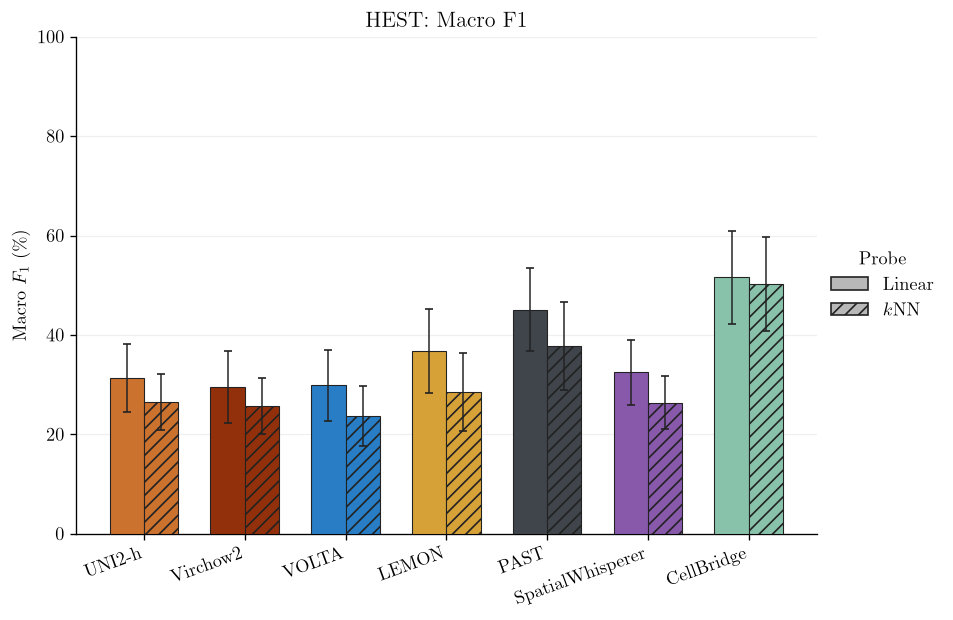

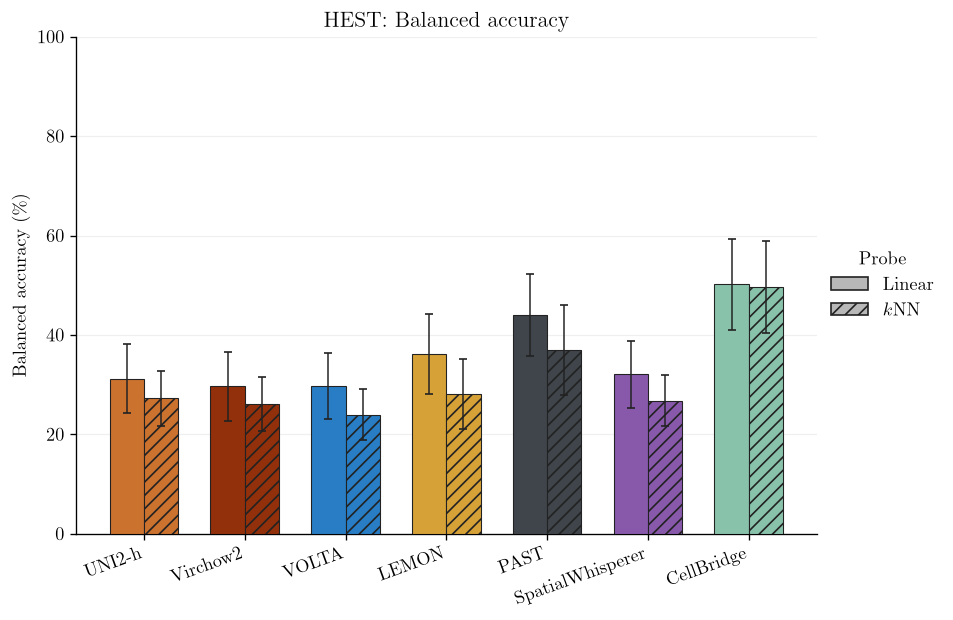

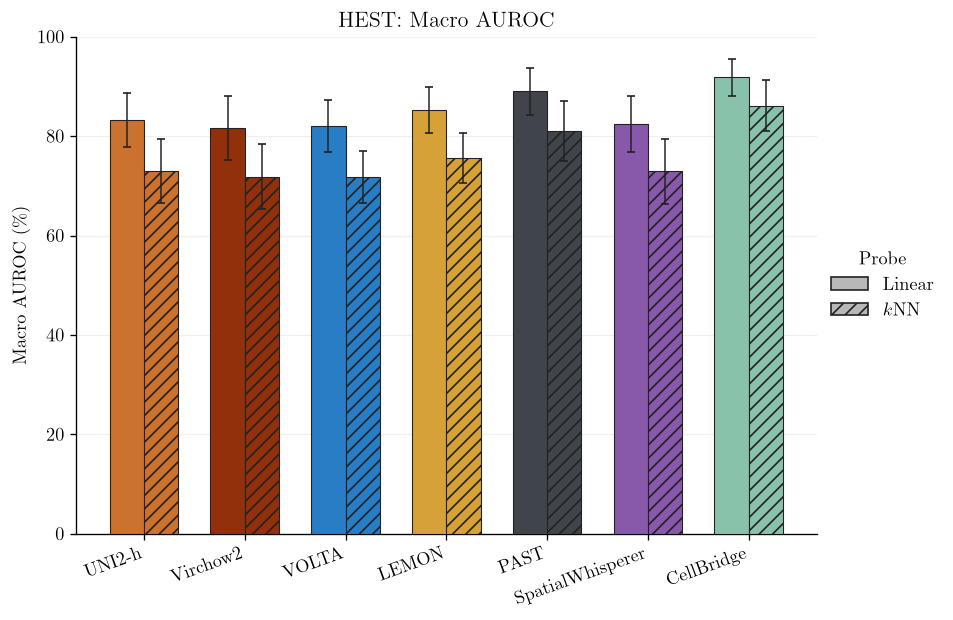

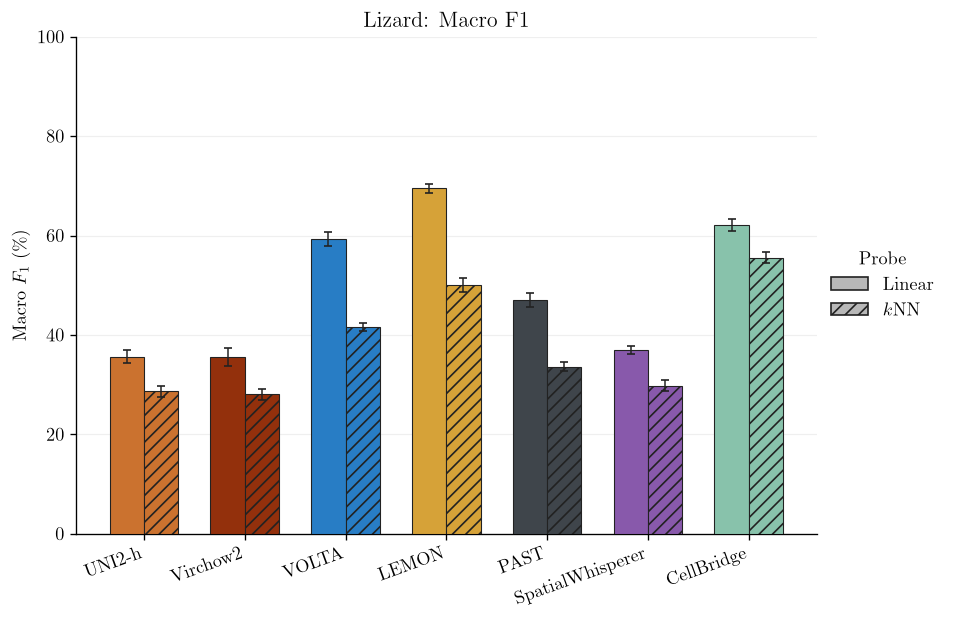

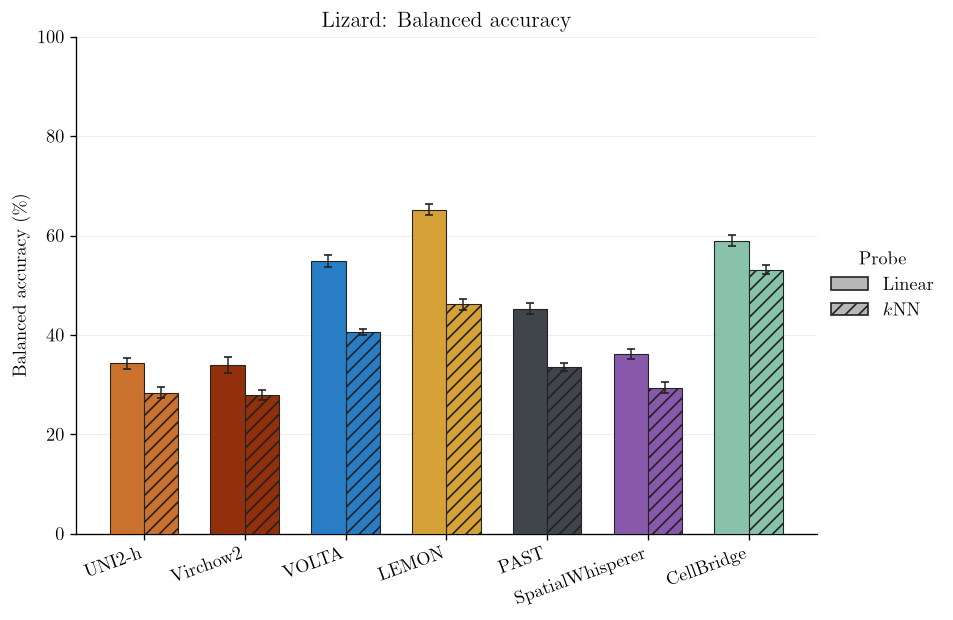

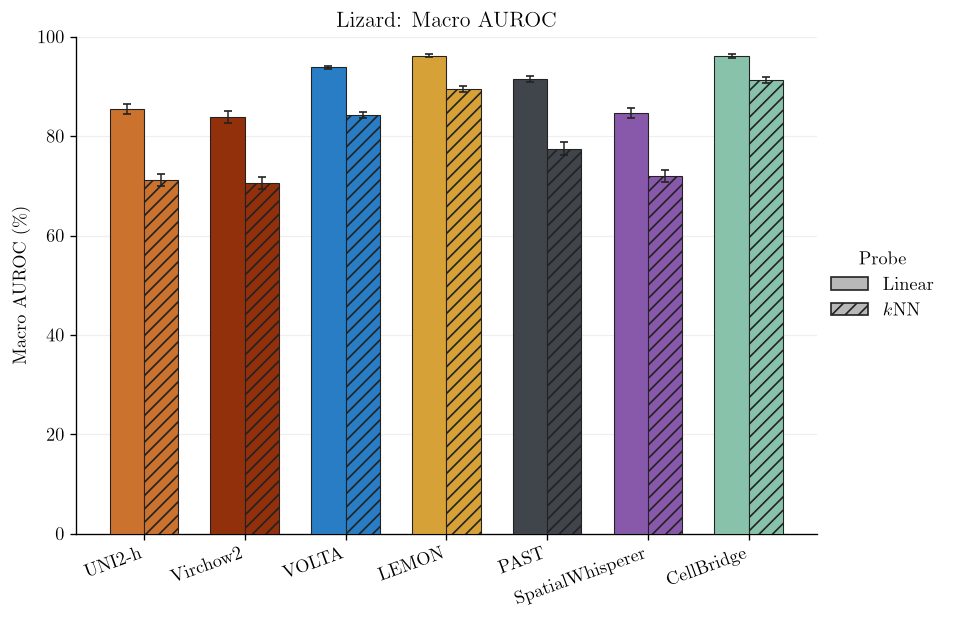

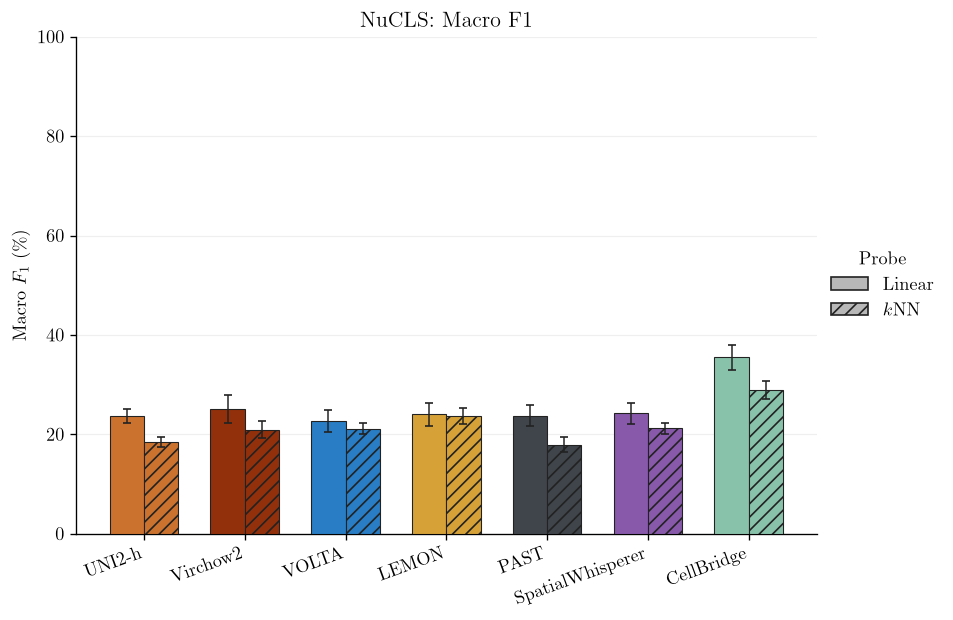

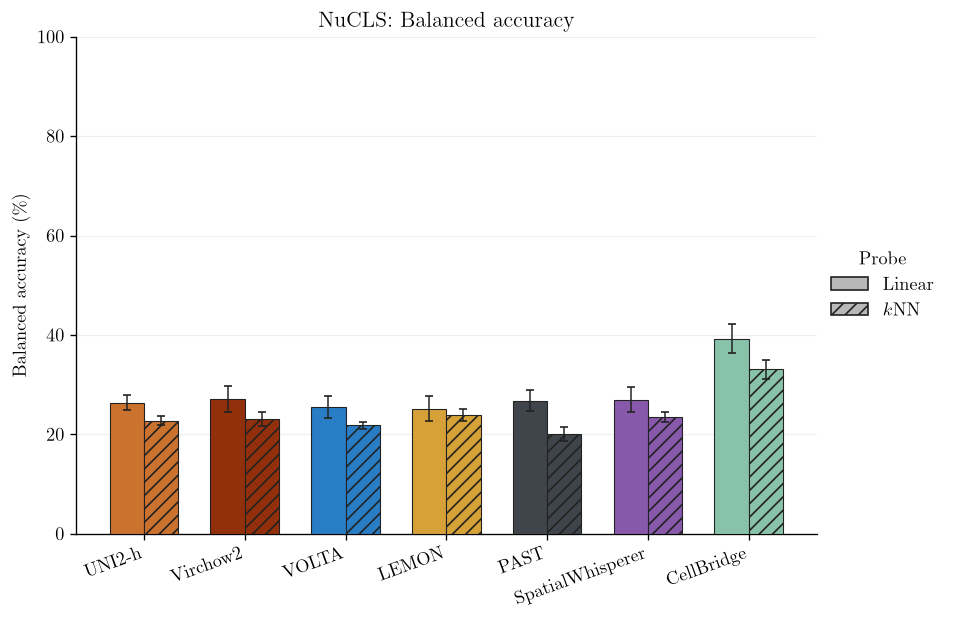

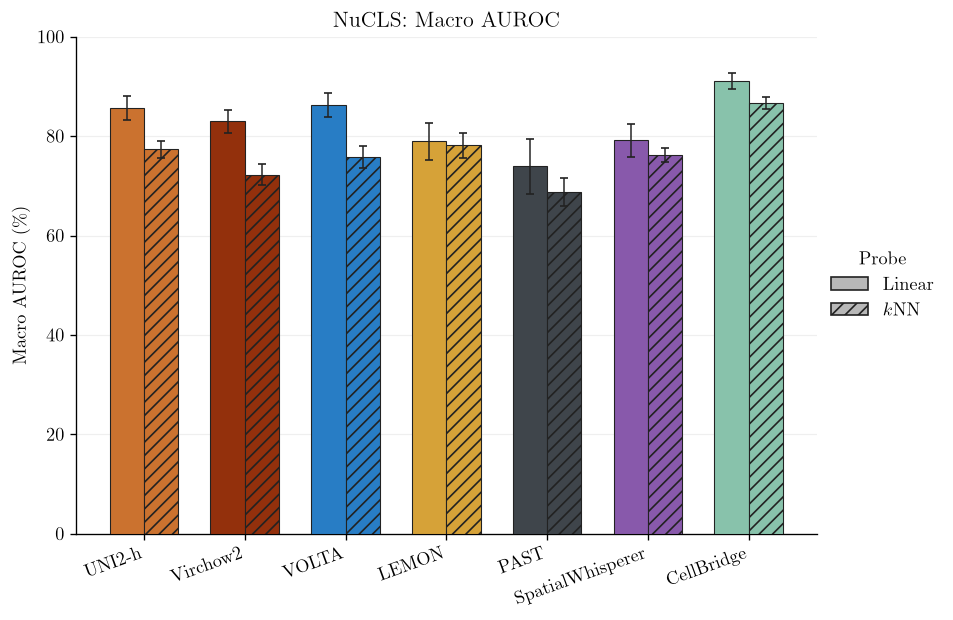

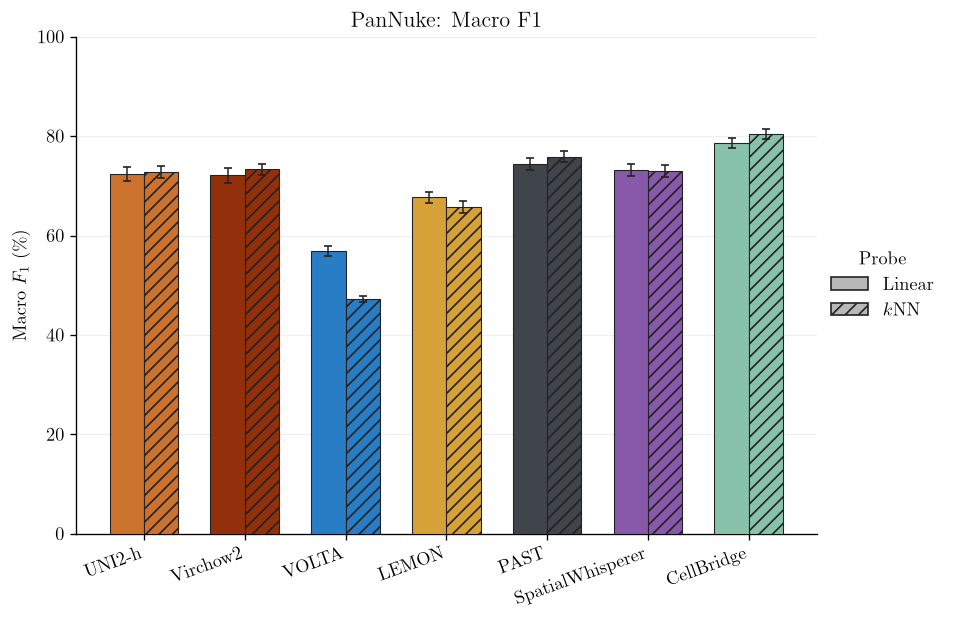

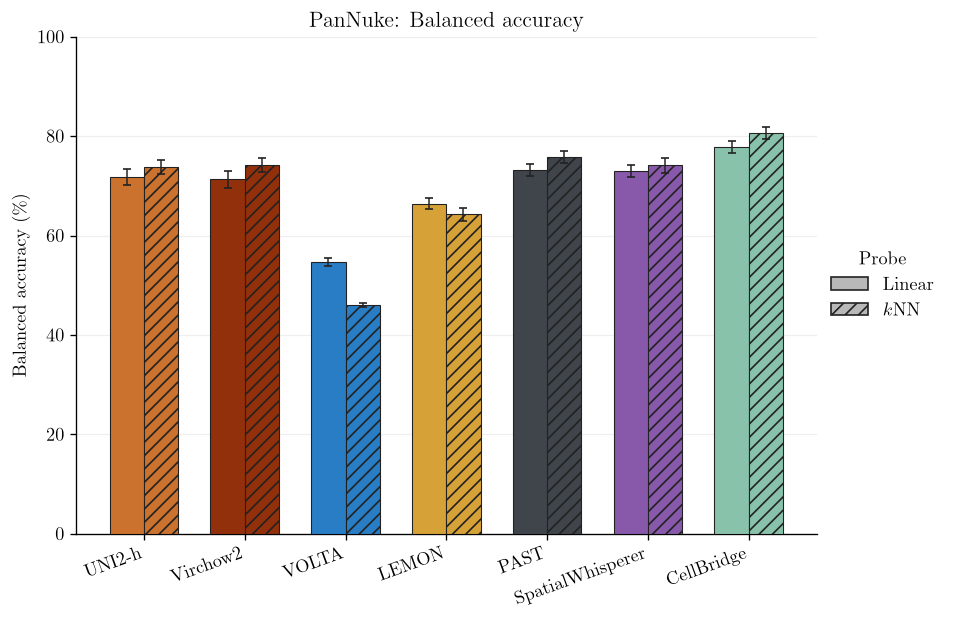

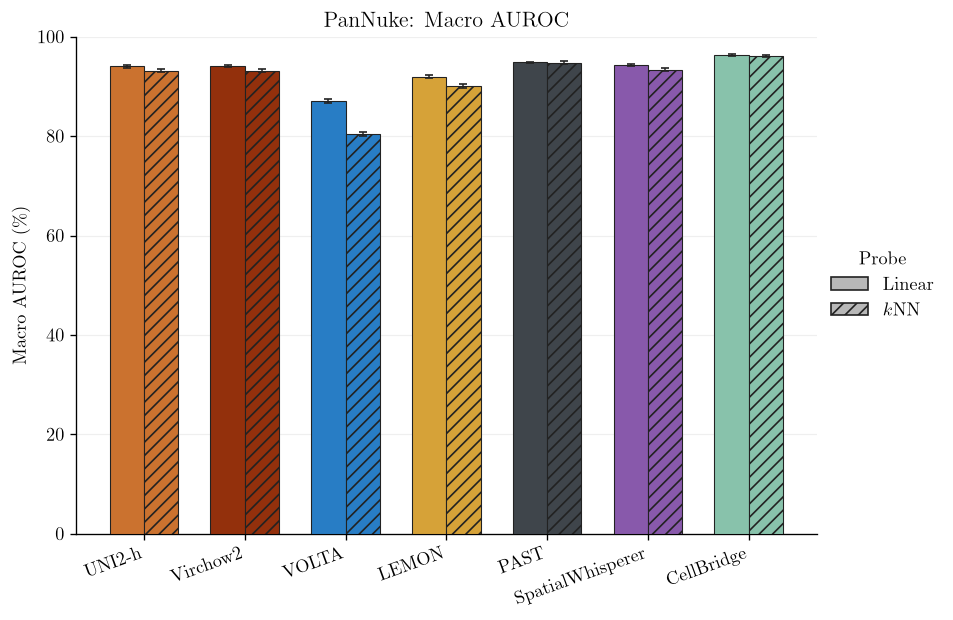

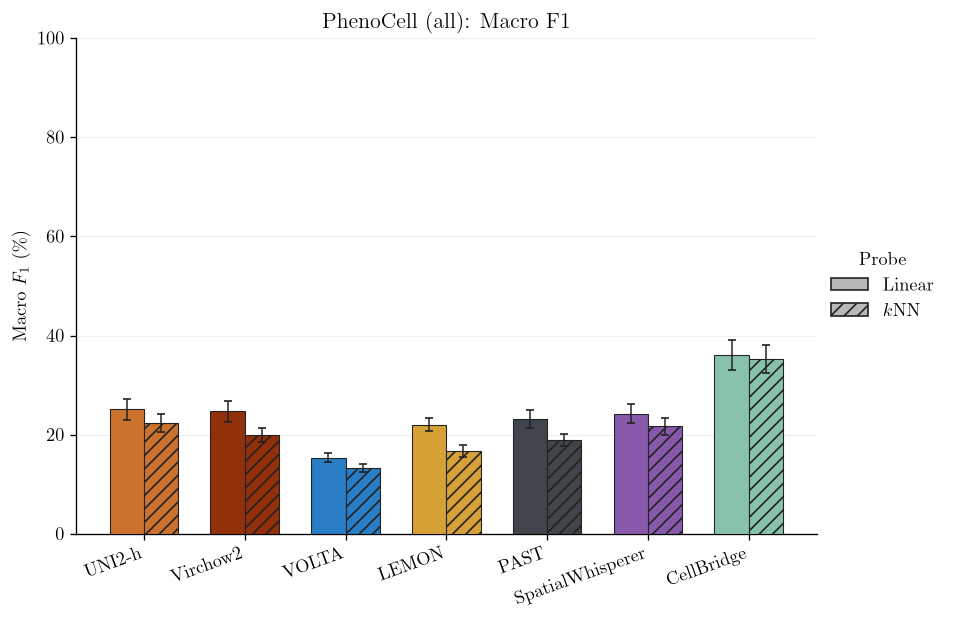

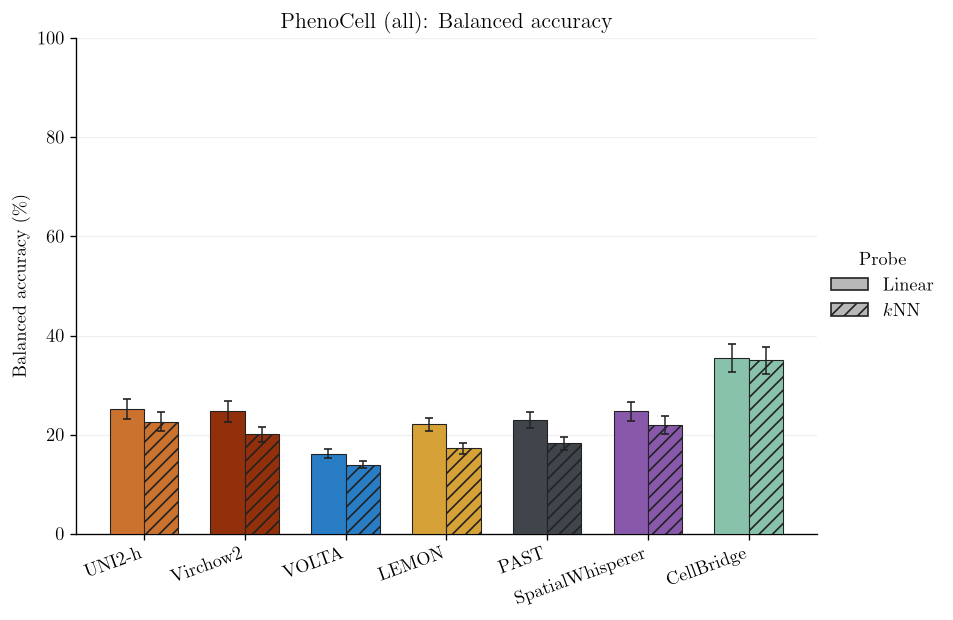

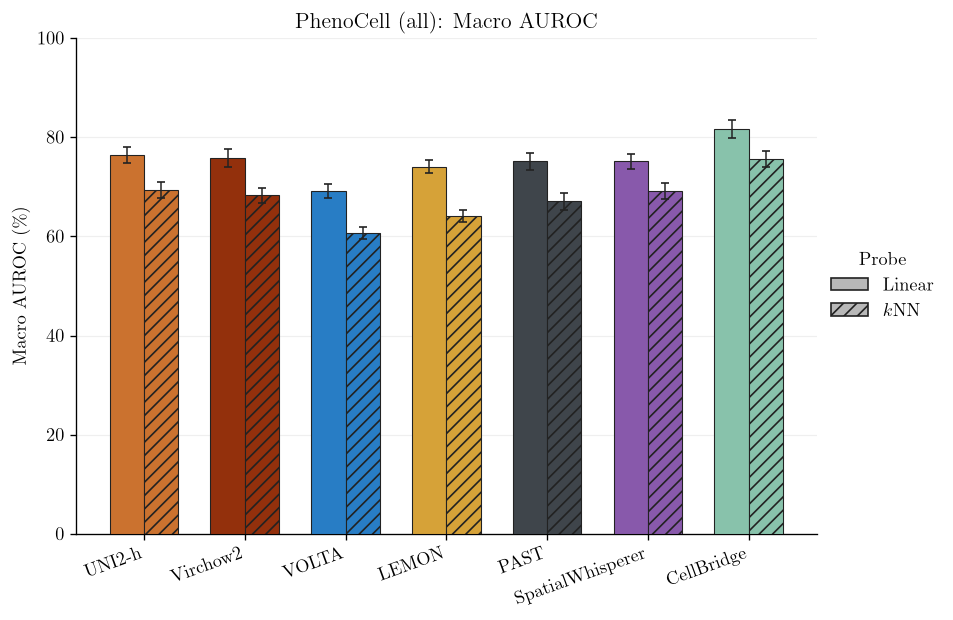

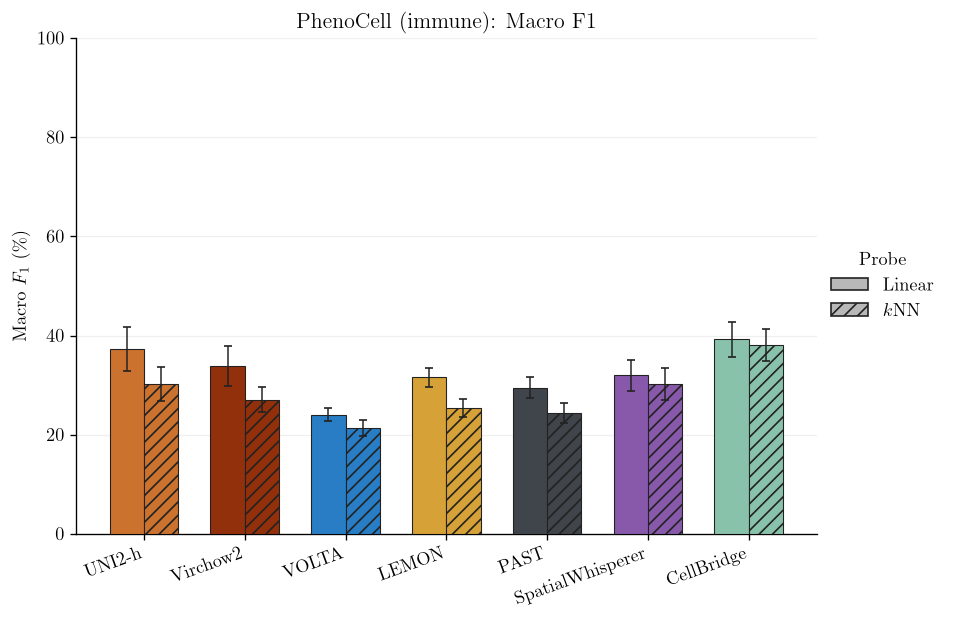

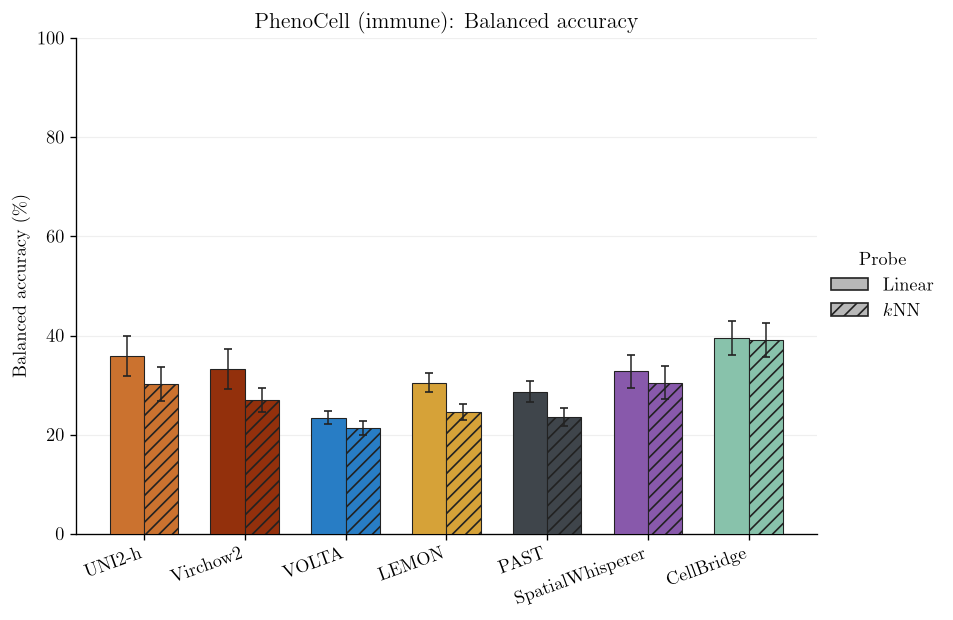

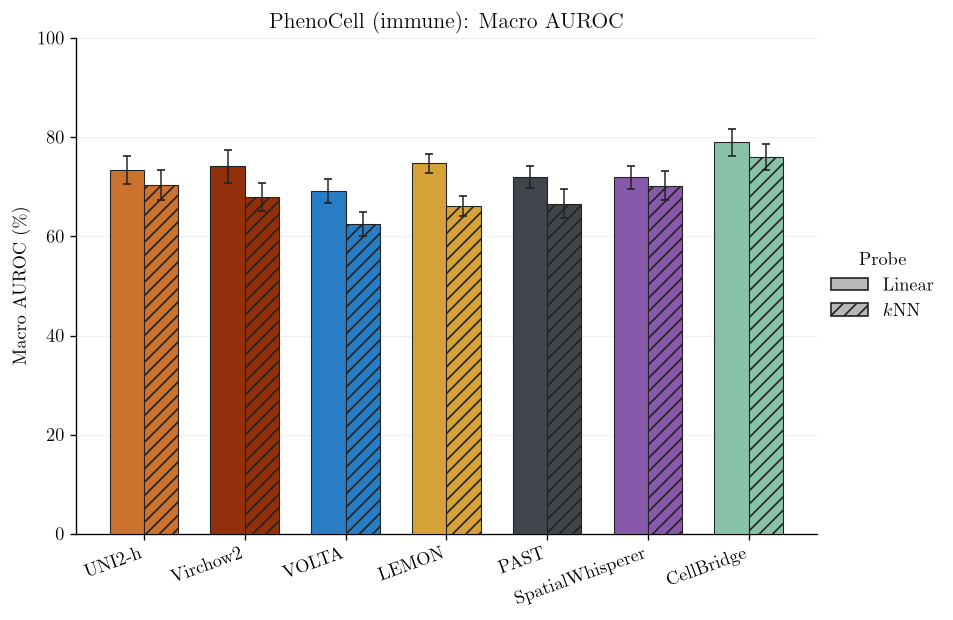

In [8]:
PLOT_METHODS = [
    "UNI2-h",
    "Virchow2",
    "VOLTA",
    "LEMON",
    "PAST",
    "SpatialWhisperer",
    "CellBridge",
]
METHOD_COLORS = {
    "UNI2-h": "#CB722F",
    "Virchow2": "#93300C",
    "VOLTA": "#287DC5",
    "LEMON": "#D6A238",
    "PAST": "#3F454B",
    "SpatialWhisperer": "#8859AB",
    "CellBridge": "#88C2AB",
}
FIGURE_PROBES = ["linear", "knn"]
PROBE_LABELS = {"linear": "Linear", "knn": r"$k$NN"}
PROBE_HATCHES = {"linear": "", "knn": "///"}
METRIC_AXIS_LABELS = {
    "macro_f1": r"Macro $F_1$ (\%)",
    "balanced_accuracy": r"Balanced accuracy (\%)",
    "macro_auroc": r"Macro AUROC (\%)",
}
PLOT_COLUMNS = [
    ("hest", "all", "HEST", "hest"),
    ("lizard", "all", "Lizard", "lizard"),
    ("nucls", "all", "NuCLS", "nucls"),
    ("pannuke", "all", "PanNuke", "pannuke"),
    ("phenocell", "all", "PhenoCell (all)", "phenocell_all"),
    ("phenocell", "immune", "PhenoCell (immune)", "phenocell_immune"),
]


def plot_downstream_metric(dataset, task, dataset_label, slug, metric):
    column_key = (dataset, task, dataset_label)
    probe_values = {}
    probe_errors = {}
    for probe in FIGURE_PROBES:
        values, errors = classification_grid([column_key], metric, probe)
        probe_values[probe] = values[dataset_label].reindex(PLOT_METHODS)
        probe_errors[probe] = errors[dataset_label].reindex(PLOT_METHODS)
        missing = probe_values[probe].loc[lambda x: x.isna()].index.tolist()
        if missing:
            raise ValueError(
                f"Missing {probe} {metric} results for {dataset_label}: {missing}"
            )

    x = np.arange(len(PLOT_METHODS), dtype=float)
    width = 0.34 if len(FIGURE_PROBES) == 2 else 0.58
    fig, ax = plt.subplots(figsize=(9.4, 5.3))
    for index, probe in enumerate(FIGURE_PROBES):
        offset = (index - (len(FIGURE_PROBES) - 1) / 2) * width
        bars = ax.bar(
            x + offset,
            100 * probe_values[probe].to_numpy(),
            width=width,
            yerr=100 * probe_errors[probe].to_numpy(),
            capsize=2.5,
            color=[METHOD_COLORS[method] for method in PLOT_METHODS],
            edgecolor="#222222",
            linewidth=0.65,
            error_kw={"elinewidth": 0.9, "ecolor": "#222222"},
            zorder=3,
        )
        for bar in bars:
            bar.set_hatch(PROBE_HATCHES[probe])

    ax.set_xticks(x, PLOT_METHODS, rotation=20, ha="right")
    ax.set_ylabel(METRIC_AXIS_LABELS[metric])
    ax.set_title(f"{dataset_label}: {METRIC_LABELS[metric]}")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.20, linewidth=0.7)
    ax.set_axisbelow(True)
    ax.legend(
        handles=[
            Patch(
                facecolor="#B8B8B8",
                edgecolor="#222222",
                hatch=PROBE_HATCHES[probe],
                label=PROBE_LABELS[probe],
            )
            for probe in FIGURE_PROBES
        ],
        title="Probe",
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        borderaxespad=0,
    )
    fig.tight_layout(rect=(0, 0, 0.86, 1))
    if SAVE_FIGURES:
        for suffix in ("png", "pdf"):
            fig.savefig(
                FIGURE_DIR / f"downstream_{slug}_{metric}.{suffix}",
                bbox_inches="tight",
            )
    plt.show()


for dataset, task, dataset_label, slug in PLOT_COLUMNS:
    for metric in CLASSIFICATION_METRICS:
        plot_downstream_metric(dataset, task, dataset_label, slug, metric)


## Raw rows

Use these frames for follow-up analyses without reloading files. Source paths are retained for provenance.

In [9]:
display(classification.head())
display(uncertainty.head())

,dataset,sample_id,method,arm,task,probe,n_features,n_train,n_validation,n_reference,n_test,n_classes,n_neighbors,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_auroc,version,paper_method,source_path,result_id,C,selection_macro_f1
0,hest,TENX116,cellbridge,lora_adapted,all,knn,256,149478,0,149478,37369,14,20.0,0.552945,0.405048,0.408638,0.541744,0.816731,cells_10k,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...,NaN,NaN
1,hest,TENX116,cellbridge,lora_adapted,all,linear,256,149478,0,149478,37369,14,NaN,0.582970,0.423996,0.432718,0.574529,0.892176,cells_10k,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...,10.0,0.546320
2,hest,TENX116,cellbridge,lora_projected,all,knn,384,149478,0,149478,37369,14,20.0,0.537504,0.402778,0.405357,0.534090,0.814224,cells_10k,CellBridge 10K (projected),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...,NaN,NaN
3,hest,TENX116,cellbridge,lora_projected,all,linear,384,149478,0,149478,37369,14,NaN,0.580428,0.420991,0.428613,0.571438,0.889044,cells_10k,CellBridge 10K (projected),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...,1.0,0.546117
4,hest,TENX187,cellbridge,lora_adapted,all,knn,256,316198,0,316198,79049,17,20.0,0.726069,0.448830,0.446980,0.713880,0.839751,cells_10k,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...,NaN,NaN


,metric,estimate,bootstrap_se,ci_2_5,ci_97_5,n_classes_scored,n_bootstrap_finite,n_test_groups,min_class_group_count,min_test_support,n_bootstrap,seed,group_column,group_regex,method,version,dataset,arm,task,probe,sample_id,paper_method,source_path,result_id
0,accuracy,0.801957,0.015860,0.771404,0.834297,NaN,1000,70,48,20,1000,0,sample_id,NaN,cellbridge,cells_10k,lizard,lora_adapted,all,knn,NaN,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...
1,balanced_accuracy,0.499552,0.010324,0.478086,0.518099,NaN,1000,70,48,20,1000,0,sample_id,NaN,cellbridge,cells_10k,lizard,lora_adapted,all,knn,NaN,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...
2,macro_f1,0.522052,0.012076,0.497243,0.544128,NaN,1000,70,48,20,1000,0,sample_id,NaN,cellbridge,cells_10k,lizard,lora_adapted,all,knn,NaN,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...
3,weighted_f1,0.795735,0.015908,0.764846,0.827755,NaN,1000,70,48,20,1000,0,sample_id,NaN,cellbridge,cells_10k,lizard,lora_adapted,all,knn,NaN,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...
4,macro_auroc,0.900241,0.006668,0.884450,0.910028,6.0,1000,70,48,20,1000,0,sample_id,NaN,cellbridge,cells_10k,lizard,lora_adapted,all,knn,NaN,CellBridge 10K (adapted),/lustre/scratch126/cellgen/lotfollahi/so25/out...,/lustre/scratch126/cellgen/lotfollahi/so25/out...
